# Figures 2–6 and Table 1

Rendering only: every panel reads pre-computed results from `data/`, and **every input file is chosen in the Settings cell below**. No model is fitted here. Files in `data/restricted/` are participant-level and not included (see README). Figures are written into `figures/`. Each section re-imports and reloads its own inputs, so sections can be run independently.

## Imports

In [1]:
import importlib
import json
import math
import os
import pickle
import re
import time

import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator, MultipleLocator
from matplotlib.transforms import blended_transform_factory
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import chi2, wilcoxon
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

import fig_store
import plot_helpers as L

## 0. Settings — which file each figure reads

Nothing else in the notebook hard-codes a filename: each load site calls `F('<key>')`.

* edit `FILES` below, then re-run the settings cell **and** the cells of the figure you changed
* `DATA_DIR` re-roots every relative path; `FIGOUT` is the output folder
* the printed table shows whether each input is present

In [2]:
# ======================= SETTINGS BOX — one input file per figure =======================
# This notebook is PLOT-ONLY: every panel reads a pre-computed artifact from disk. Change a
# path here, re-run this cell, then re-run that figure's cells. F('key') resolves a path:
#   env FIG_FILE_<KEY>  >  FILES[key]  ,  relative paths joined onto DATA_DIR.

DATA_DIR = 'data'                                              # root for every relative path below
FIGOUT   = os.environ.get('FIGOUT', 'figures')    # where the PNG/PDF panels are written

FILES = {
    # ---- shared ---------------------------------------------------------------------------
    'cohort'          : 'restricted/cohort.csv',  # cohort (Fig 2 panel C + Table 1)
    'figure_data'     : 'figure_panels.csv',                      # fig_store panel store (Fig 2, Fig 6A)
    # ---- Figure 2 / Table 1 ---------------------------------------------------------------
    'covariates'      : 'restricted/baseline_covariates.csv',    # baseline covariate means
    'table1_out'      : 'table1.csv',           # WRITTEN by the Table-1 cell

    # ---- Figure 3 — CGM variability, women vs male control --------------------------------
    'iglu_plotdata'   : 'fig3_cgm_trends.csv',   # binned + spline + p per metric
    'iglu_results'    : 'fig3_cgm_stats.csv',         # male FDR q's re-mapped onto the men row
    # ---- Figure 4 — PPGR population -------------------------------------------------------
    'fig4_store'      : 'restricted/fig4_meals.pkl',         # RESP + binary + grids + splines
    'sleep_loc'       : 'fig4_hourly_cv.csv',   # hourly CV by phase (panel A)
    'sleep_cv'        : 'restricted/fig4_day_night_cv.csv',     # per-woman phase x window CV (panel B)

    # ---- Figure 5 — within-woman confirmation ---------------------------------------------
    'fig5_grids'      : 'fig5_grids.csv',         # buffer x window grid (Fig 4 + Fig 5)
    'fig5_deltas'     : 'restricted/fig5_deltas.csv',
    'fig5_phase'      : 'restricted/fig5_paired.csv',
    # ---- Figure 6 — behavioral robustness -------------------------------------------------
    'exercise_summary': 'fig6_activity_summary.csv',     # activity summary table
    'activity_pred'   : 'fig6_activity_curves.csv',       # unadj vs activity-adjusted curves
    'activity_inter'  : 'fig6_activity_interaction.csv',       # cycle x activity interaction LRTs
    'fig3_robustness' : 'fig6_covariate_interaction.csv',            # cycle x covariate interaction LRTs
}
OUTPUTS = {'table1_out'}          # written, not read — not expected to exist beforehand

def F(key):
    """Resolved path for a SETTINGS BOX key. env FIG_FILE_<KEY> wins, then FILES[key]."""
    p = os.environ.get('FIG_FILE_' + key.upper(), FILES[key])
    return p if os.path.isabs(p) else os.path.join(DATA_DIR, p)

os.makedirs(FIGOUT, exist_ok=True)
for _k in FILES:
    _ok = os.path.exists(F(_k)) or _k in OUTPUTS
    print(f"{'ok     ' if _ok else 'MISSING'}  {_k:<17} {FILES[_k]}")

ok       cohort            restricted/cohort.csv
ok       figure_data       figure_panels.csv
ok       covariates        restricted/baseline_covariates.csv
ok       table1_out        table1.csv
ok       iglu_plotdata     fig3_cgm_trends.csv
ok       iglu_results      fig3_cgm_stats.csv
ok       fig4_store        restricted/fig4_meals.pkl
ok       sleep_loc         fig4_hourly_cv.csv
ok       sleep_cv          restricted/fig4_day_night_cv.csv
ok       fig5_grids        fig5_grids.csv
ok       fig5_deltas       restricted/fig5_deltas.csv
ok       fig5_phase        restricted/fig5_paired.csv
ok       exercise_summary  fig6_activity_summary.csv
ok       activity_pred     fig6_activity_curves.csv
ok       activity_inter    fig6_activity_interaction.csv
ok       fig3_robustness   fig6_covariate_interaction.csv


---
## Figure 2 - cohort / descriptives

# Figure 2 - Cohort Characteristics Across the Menstrual Cycle

Assembled **entirely from the shared results store** (`data/figure_panels.csv`); this notebook only **loads and replots** - no analysis is re-run.

Panels: **A** Age, **B** BMI (distribution, balanced across cycle); **C** cycle length; **D** total energy and **E** carbohydrate intake; **F, G** two serum metabolites - trend panels in the spline style (binned mean ± SEM + moving average + cyclic spline + peak/nadir windows + phase bar). The x-axis label is shown only on the lowest panel of each column.

## 1. Load shared results store

In [3]:
importlib.reload(fig_store)  # pick up edits without kernel restart
fig_store.FIG_DATA = F('figure_data')   # SETTINGS BOX chooses which panel store to read

sns.set_style('whitegrid')
METAB_IDS = ['3.31_349.1117m/z_189.06', '3.67_495.2965m/z_214.04']

store = fig_store.load()
if store.empty:
    print(f"{F('figure_data')} is empty — run the save-cell in each source notebook first.")
else:
    print('Sources present:', sorted(store['source'].unique()))

Sources present: ['cgm_men', 'cgm_women', 'cohort', 'diet', 'exercise', 'metabolites']


## 2. Panel drawers (replot source data)

In [4]:
BAR_IN = 0.28   # phase-bar height in INCHES (as Figures 3, 4, 6), so taller panels don't get a thicker bar
def _phase_bar(ax):
    # needs the final axes size: call after subplots_adjust
    ax.set_xlim(-5, 105)
    tr = ax.get_xaxis_transform()
    _f = BAR_IN / (ax.get_position().height * ax.figure.get_figheight())
    ax.fill_between([-5, 50], -_f, 0, color='#eb63e0', alpha=0.5, transform=tr, clip_on=False)
    ax.fill_between([50, 105], -_f, 0, color='#051281', alpha=0.5, transform=tr, clip_on=False)
    ax.text(25, -_f * 0.64, 'Follicular', transform=tr, ha='center', color='white', fontweight='bold', fontsize=9)
    ax.text(75, -_f * 0.64, 'Luteal', transform=tr, ha='center', color='white', fontweight='bold', fontsize=9)

def _finish(ax, ylabel, ygrid_only=False, show_xlabel=True):
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.tick_params(axis='x', pad=BAR_IN * 72 + 5)   # clear the bar, then the same gap as Figures 3, 4, 6
    ax.grid(True, axis='y' if ygrid_only else 'both', linestyle=':', alpha=0.4)
    if show_xlabel:
        ax.set_xlabel('Cycle progress (%)')
    else:
        # hide the 0/25/50/75/100 tick labels on non-bottom-row panels
        ax.tick_params(axis='x', labelbottom=False)

def _missing(ax, source, metric, letter):
    ax.text(-0.05, 1.1, letter, transform=ax.transAxes, fontsize=12, fontweight='bold', va='bottom', ha='right')
    ax.text(0.5, 0.5, f'No data for\n{source} / {metric}\n(run its save-cell)',
            ha='center', va='center', transform=ax.transAxes, fontsize=9, color='crimson')
    ax.set_xticks([])

def draw_trend(ax, source, metric, letter, label_override=None, ylabel_override=None, show_xlabel=True):
    d = fig_store.load(source, metric)
    if d.empty:
        return _missing(ax, source, metric, letter)
    label = label_override or str(d['label'].iloc[0])
    b = d[d['series'] == 'binned'].sort_values('x')
    s = d[d['series'] == 'spline'].sort_values('x')
    pfdr, pperm = d['p_fdr'].iloc[0], d['p_perm'].iloc[0]
    verdict = str(d['verdict'].iloc[0])

    ax.text(-0.05, 1.1, letter, transform=ax.transAxes, fontsize=12, fontweight='bold', va='bottom', ha='right')
    if len(b):
        ax.axhline(b['y'].mean(), color='gray', lw=1.5, alpha=0.5)
        ax.errorbar(b['x'], b['y'], yerr=b['sem'], fmt='none', ecolor='blue', alpha=0.3)
        ax.scatter(b['x'], b['y'], color='blue', s=20, alpha=0.6)
        smooth = b['y'].rolling(3, center=True, min_periods=1).mean()
        ax.plot(b['x'], smooth, color='#8ba5fc', lw=2.5, alpha=0.8)
    if len(s):
        # Significant = permutation-confirmed (cycle-specific). Prefer the perm p;
        # fall back to the explicit verdict string, else the FDR q.
        if pd.notna(pperm):
            sig = pperm < 0.05
        elif verdict:
            sig = verdict == 'CONFIRMED TREND'
        else:
            sig = pd.notna(pfdr) and pfdr < 0.05
        # navy solid = significant; gray faint = not
        ax.plot(s['x'], s['y'], color='navy' if sig else 'gray',
                lw=3, alpha=1.0 if sig else 0.5)
        # peak / nadir windows only when significant
        if sig:
            xv, yv = s['x'].values, s['y'].values
            ax.axvspan(xv[yv.argmax()] - 1.5, xv[yv.argmax()] + 1.5, color='#D67173', alpha=0.3, zorder=0)
            ax.axvspan(xv[yv.argmin()] - 1.5, xv[yv.argmin()] + 1.5, color='#78C9C7', alpha=0.3, zorder=0)

    sub = []
    if pd.notna(pfdr):
        sub.append(f'q={pfdr:.3f}' if pfdr >= 0.001 else f'q={pfdr:.2e}')
    if pd.notna(pperm):
        sub.append(f'perm p={pperm:.2e}' if pperm < 0.001 else f'perm p={pperm:.3f}')
    ax.set_title(label.split(' (')[0] + ('\n' + ' | '.join(sub) if sub else ''), fontsize=10)
    _phase_bar(ax)
    _finish(ax, ylabel_override or label, show_xlabel=show_xlabel)

def draw_dist(ax, source, metric, letter, n_bins=10, ylabel_override=None, show_xlabel=True):
    d = fig_store.load(source, metric)
    pts = d[d['series'] == 'points'] if not d.empty else d
    if pts.empty:
        return _missing(ax, source, metric, letter)
    label = str(pts['label'].iloc[0])
    bp = pts['balance_p'].iloc[0]
    edges = np.linspace(0, 100, n_bins + 1)
    centers = (edges[:-1] + edges[1:]) / 2
    pts = pts.copy()
    pts['cb'] = pd.cut(pts['x'], bins=edges, include_lowest=True)
    groups, pos = [], []
    grouped = dict(tuple(pts.groupby('cb', observed=False)))
    for c, interval in zip(centers, pts['cb'].cat.categories):
        g = grouped.get(interval)
        if g is not None and len(g) > 0:
            groups.append(g['y'].values)
            pos.append(c)

    ax.text(-0.05, 1.1, letter, transform=ax.transAxes, fontsize=12, fontweight='bold', va='bottom', ha='right')
    bpx = ax.boxplot(groups, positions=pos, widths=(100 / n_bins) * 0.7,
                     patch_artist=True, showfliers=True, manage_ticks=False,
                     flierprops=dict(marker='o', markersize=4, markerfacecolor='gray',
                                     markeredgecolor='none', alpha=0.4))
    for box in bpx['boxes']:
        box.set(facecolor='lightsteelblue', alpha=0.85)
    for med in bpx['medians']:
        med.set(color='navy')

    title = label.split(' (')[0]
    if pd.notna(bp):
        title += (f'\np={bp:.2e}' if bp < 0.001 else f'\np={bp:.3f}')
    ax.set_title(title, fontsize=10)
    _phase_bar(ax)
    _finish(ax, ylabel_override or label, ygrid_only=False, show_xlabel=show_xlabel)

def draw_hist(ax, data, title, xlabel, letter, color='#051281', bins=None, xticks=None, show_xlabel=True):
    """Plain count histogram for subject-level cycle-timing variables (x = days, no phase bar).
    Grid and integer ticks match the age/bmi (draw_dist/_finish) panels."""
    ax.text(-0.05, 1.1, letter, transform=ax.transAxes, fontsize=12, fontweight='bold', va='bottom', ha='right')
    ax.hist(data, bins=bins, color=color, alpha=0.85, edgecolor='white')
    ax.set_title(title, fontsize=10)
    if xticks is not None:                                   # explicit integer ticks (e.g. 21..35)
        xticks = list(xticks)
        ax.set_xticks(xticks)
        ax.set_xlim(min(xticks) - 0.5, max(xticks) + 0.5)
    else:
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{int(round(v))}'))  # 20 not 20.0
    ax.set_ylabel('Number of women', fontsize=10)
    ax.grid(True, axis='both', linestyle=':', alpha=0.4)     # same grid as age/bmi
    if show_xlabel:
        ax.set_xlabel(xlabel, fontsize=10)

## 3. Figure 2

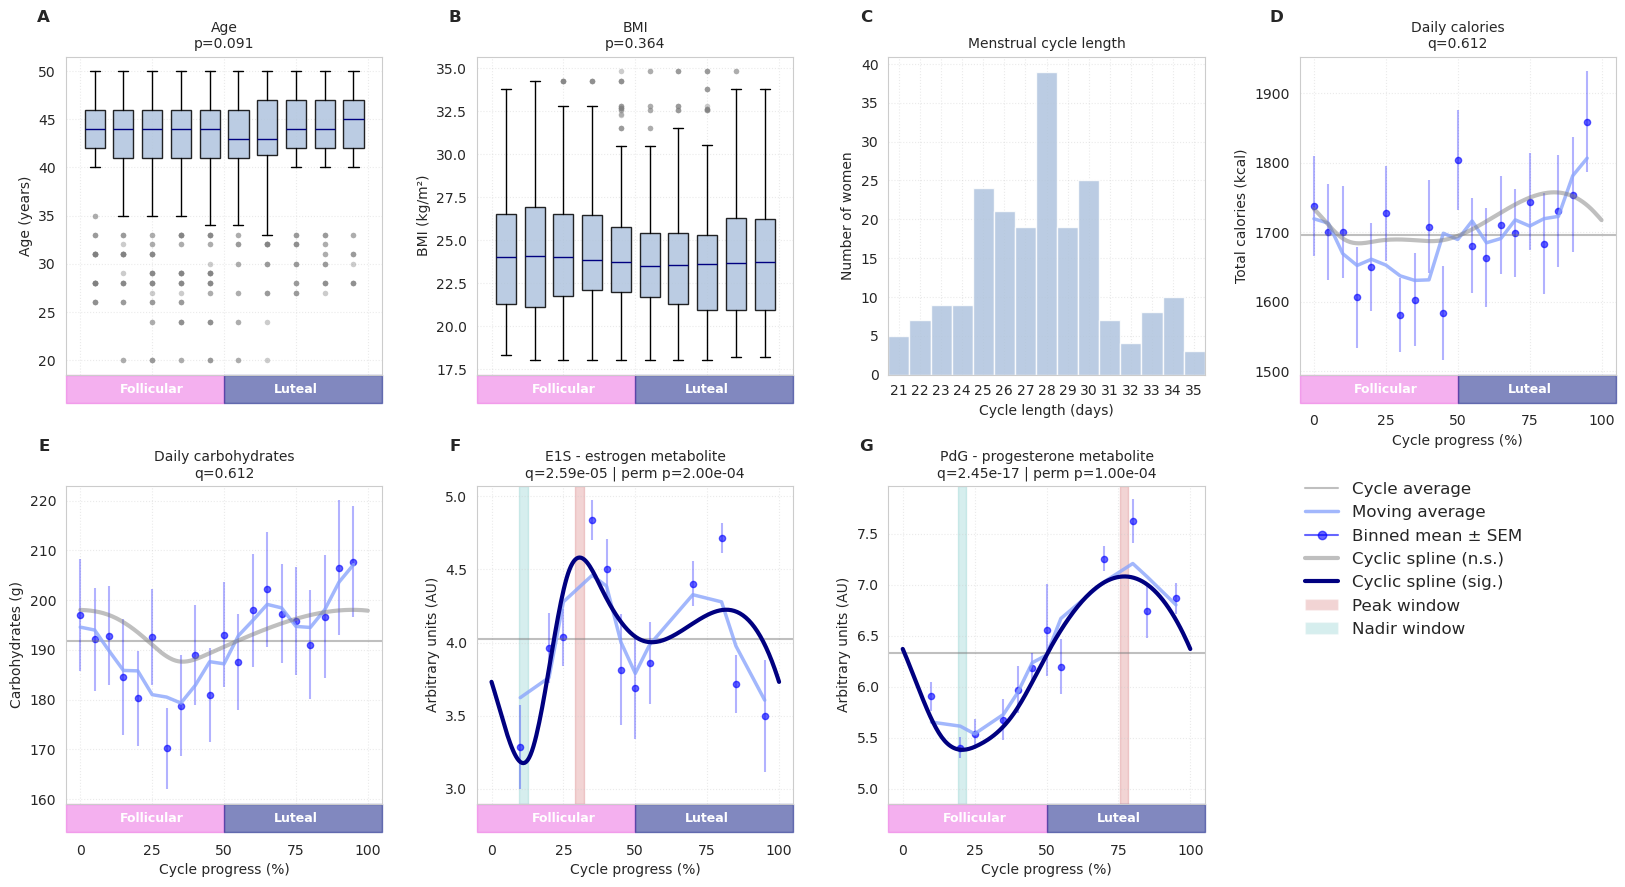

In [5]:
FIGOUT = globals().get('FIGOUT') or os.environ.get('FIGOUT', 'figures'); os.makedirs(FIGOUT, exist_ok=True)   # set in the SETTINGS BOX (top of notebook)

# 7 panels in a 2x4 grid: age, bmi, energy, carbs, cycle-length, 2x metabolites.
# Shared legend in the spare (8th) cell.
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()
_=plt.subplots_adjust(hspace=0.35, wspace=0.3, top=0.92, bottom=0.09)   # before drawing: the phase bar is sized from the final axes

draw_dist (axes[0], 'cohort', 'age', 'A', show_xlabel=False)
draw_dist (axes[1], 'cohort', 'bmi', 'B', ylabel_override='BMI (kg/m²)', show_xlabel=False)
_clen = pd.read_csv(F('cohort')).drop_duplicates('RegistrationCode')['menstrual_cycle_cal'].dropna()
draw_hist(axes[2], _clen, 'Menstrual cycle length', 'Cycle length (days)', 'C', color='lightsteelblue', bins=np.arange(20.5, 36.5, 1), xticks=range(21, 36), show_xlabel=True)
draw_trend(axes[3], 'diet', 'Energy', 'D', label_override='Daily calories', ylabel_override='Total calories (kcal)', show_xlabel=True)
draw_trend(axes[4], 'diet', 'Carbohydrates', 'E', label_override='Daily carbohydrates', ylabel_override='Carbohydrates (g)', show_xlabel=True)
draw_trend(axes[5], 'metabolites', METAB_IDS[0], 'F', label_override='E1S - estrogen metabolite', ylabel_override='Arbitrary units (AU)', show_xlabel=True)
draw_trend(axes[6], 'metabolites', METAB_IDS[1], 'G', label_override='PdG - progesterone metabolite', ylabel_override='Arbitrary units (AU)', show_xlabel=True)
for _ax in (axes[5], axes[6]):   # F and G: same y-tick step
    _ax.yaxis.set_major_locator(MultipleLocator(0.5))
# G: put its first y-tick at the same height above the panel bottom as F's
_lo, _hi = axes[5].get_ylim(); _frac = (np.ceil(_lo / 0.5) * 0.5 - _lo) / (_hi - _lo)
_lo, _hi = axes[6].get_ylim(); _t0 = np.floor(_lo / 0.5) * 0.5
axes[6].set_ylim((_t0 - _frac * _hi) / (1 - _frac), _hi)

legend_elems = [
    Line2D([0], [0], color='gray', lw=1.5, alpha=0.5),
    Line2D([0], [0], color='#8ba5fc', lw=2.5, alpha=0.8),
    Line2D([0], [0], marker='o', color='blue', ls='-', markersize=6, alpha=0.6),
    Line2D([0], [0], color='gray', lw=3, alpha=0.5),
    Line2D([0], [0], color='navy', lw=3),
    Patch(facecolor='#D67173', alpha=0.3),
    Patch(facecolor='#78C9C7', alpha=0.3),
]
legend_labels = ['Cycle average', 'Moving average', 'Binned mean ± SEM',
                 'Cyclic spline (n.s.)', 'Cyclic spline (sig.)',
                 'Peak window', 'Nadir window']
axes[7].axis('off')
_=axes[7].legend(legend_elems, legend_labels, loc='upper left',
                 bbox_to_anchor=(-0.03, 1.06), fontsize=12, frameon=False)

os.makedirs('figures', exist_ok=True)
fig.savefig(f'{FIGOUT}/Figure2.png', dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig(f'{FIGOUT}/Figure2.pdf', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## Table 1 — baseline characteristics of the study population

In [6]:
# --- Table 1: baseline characteristics of the cohort (10K Table 1 format) ---
# Source: baseline covariate means, filtered to our final cohort (women only).

COV_PATH    = F('covariates')     # SETTINGS BOX
COHORT_PATH = F('cohort')         # SETTINGS BOX

cov    = pd.read_csv(COV_PATH)
cohort = pd.read_csv(COHORT_PATH)
cohort_ids = set(cohort['RegistrationCode'])
t1 = cov[cov['RegistrationCode'].isin(cohort_ids)].drop_duplicates('RegistrationCode', keep='first').copy()
N = t1['RegistrationCode'].nunique()
print(f'Cohort women with covariates: {N}/{len(cohort_ids)}')

# group -> list of (source covariate column, display label). Mirrors the published 10K
# Table 1: variable selection, order, labels and units.
SPEC = [
    ('Demographic', [
        ('age', 'Age (years)')]),
    ('Anthropometric', [
        ('BMI', 'BMI (kg/m²)'),
        ('Waist circumference', 'Waist circumference (cm)'),
        ('Sitting BP systolic', 'Sitting BP systolic (mmHg)'),
        ('Sitting BP diastolic', 'Sitting BP diastolic (mmHg)')]),
    ('Blood tests', [
        ('HbA1C (BT)', 'HbA1C (%)'),
        ('Triglycerides (BT)', 'Triglycerides (mg/dL)'),
        ('HDL cholesterol (BT)', 'HDL cholesterol (mg/dL)'),
        ('LDL cholesterol (BT)', 'LDL cholesterol (mg/dL)'),
        ('Total cholesterol (BT)', 'Total cholesterol (mg/dL)'),
        ('ALT\\GPT (BT)', 'ALT\\GPT (u/l)'),
        ('AST\\GOT (BT)', 'AST\\GOT (u/l)'),
        ('GGT (BT)', 'GGT (u/l)'),
        ('eGFR (BT)', 'eGFR')]),
    ('DXA scan', [
        ('Android tissue fat percent (DXA)', 'Android tissue fat percent (%)'),
        ('Scanned VAT mass (DXA)', 'Scanned VAT mass (g)'),
        ('Total fat mass (DXA)', 'Total fat mass (g)')]),
    ('Fundus imaging', [
        ('Average width (FI)', 'Average width (pixels)'),
        ('Fractal dimension (FI)', 'Fractal dimension'),
        ('Vessel density (FI)', 'Vessel density')]),
    ('Ultrasound', [
        ('Liver sound speed (US)', 'Liver sound speed (m/s)'),
        ('Liver viscosity (US)', 'Liver viscosity (Pa.s)'),
        ('Liver elasticity (US)', 'Liver elasticity (kPa)'),
        ('Liver attenuation (US)', 'Liver attenuation (dB/cm/MHz)'),
        ('Carotid - intima media thickness (US)', 'Carotid - intima media thickness (mm)')]),
    ('Sleep monitoring', [
        ('ODI (SM)', 'ODI'),
        ('AHI (SM)', 'AHI'),
        ('RDI (SM)', 'RDI'),
        ('Mean Oxygen Saturation (SM)', 'Mean oxygen saturation'),
        ('Total Sleep Time (SM)', 'Total sleep time (hr)'),
        ('Total Wake Time (SM)', 'Total wake time (hr)')]),
    ('Nutrition', [
        ('Median daily protein caloric intake  (DL)', 'Median daily protein caloric intake (%)'),
        ('Median daily lipid caloric intake(DL)', 'Median daily lipid caloric intake (%)'),
        ('Median daily carbohydrate caloric intake  (DL)', 'Median daily carbohydrate caloric intake (%)'),
        ('Median daily caloric intake (DL)', 'Median daily caloric intake (kcal)')]),
]

# whitespace-insensitive column resolver (source names have irregular spacing)
_norm = lambda s: re.sub(r'\s+', ' ', str(s)).strip().lower()
_lookup = {_norm(c): c for c in t1.columns}
def _col(name):
    return name if name in t1.columns else _lookup.get(_norm(name))

_patch_file = os.path.join(DATA_DIR, 'restricted', 'table1_diet_patch.json')
if os.path.exists(_patch_file):
    _patch = json.load(open(_patch_file))
    _pid, _diet_patch = _patch['RegistrationCode'], _patch['values']
    if _pid in set(t1['RegistrationCode']):
        for _src, _val in _diet_patch.items():
            _c = _col(_src)
            if _c is not None:
                t1.loc[t1['RegistrationCode'] == _pid, _c] = _val
        print('Patched diet for 1 participant (now in Nutrition rows)')

# --- age / BMI come from the COHORT file, not the baseline covariate file ---
# The baseline covariate file carries baseline-visit values (age 43.7, BMI 24.4); the analysis --
# and every age/BMI number in the manuscript -- uses the CGM-time values recorded in
# the cohort file (age 43.2 +/- 5.2, BMI 24.3 +/- 3.7). Override so Table 1
# cannot disagree with the text that cites it.
_ch = cohort.drop_duplicates('RegistrationCode', keep='first').set_index('RegistrationCode')
for _src, _cohcol in [('age', 'age'), ('BMI', 'bmi')]:
    _c = _col(_src)
    if _c is not None:
        t1[_c] = t1['RegistrationCode'].map(_ch[_cohcol])
        print(f'Table 1: {_src} sourced from cohort file '
              f'(mean {t1[_c].mean():.2f}, sd {t1[_c].std():.2f})')

# unit conversions on source columns (source 'Scanned VAT mass (DXA)' is in kg)
CONVERT = {'Scanned VAT mass (DXA)': 1000.0}

GC = f'Women (N = {N})'
rows = []
for group, items in SPEC:
    rows.append({'Characteristic': group, 'n': '', GC: ''})          # section header
    for src, label in items:
        col = _col(src)
        if col is None:
            rows.append({'Characteristic': f'  {label}', 'n': '0', GC: 'NA (not found)'}); continue
        s = t1[col].dropna() * CONVERT.get(src, 1.0)
        if s.empty:
            rows.append({'Characteristic': f'  {label}', 'n': '0', GC: 'NA'}); continue
        m, sd = s.mean(), s.std()
        d = 2 if abs(m) < 1 else 1                                    # 2 dp for fractions, else 1 dp
        rows.append({'Characteristic': f'  {label}', 'n': str(int(s.shape[0])),
                     GC: f'{m:.{d}f} ({sd:.{d}f})'})

table1 = pd.DataFrame(rows)[['Characteristic', 'n', GC]]
table1.to_csv(F('table1_out'), index=False)
print(f"Saved Table 1  (N = {N} women)")
display(table1.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

Cohort women with covariates: 209/209
Patched diet for 1 participant (now in Nutrition rows)
Table 1: age sourced from cohort file (mean 43.18, sd 5.22)
Table 1: BMI sourced from cohort file (mean 24.32, sd 3.73)
Saved Table 1  (N = 209 women)


Characteristic,n,Women (N = 209)
Demographic,,
Age (years),209,43.2 (5.2)
Anthropometric,,
BMI (kg/m²),209,24.3 (3.7)
Waist circumference (cm),208,78.4 (9.8)
Sitting BP systolic (mmHg),209,109.3 (13.8)
Sitting BP diastolic (mmHg),209,72.5 (10.0)
Blood tests,,
HbA1C (%),54,5.2 (0.3)
Triglycerides (mg/dL),98,84.6 (38.2)


---
## Figure 3 - men vs women cyclic trends

# Figure 3 — CGM glycaemic variability across the cycle: women vs male negative control

**Women** and **Men** (matched negative control) as rows, metrics as columns; each panel is drawn in the Figure 2 spline style. Below the grid, two summary forests: cycle-effect significance (I) and cyclic amplitude (J). The canonical fit drops carbohydrates from the GLMM covariates. This notebook **only loads and replots** `data/fig3_cgm_trends.csv` (binned means ± SEM, spline curve, FDR/permutation p, amplitude + CI for every modelled metric in both cohorts) and `data/fig3_cgm_stats.csv`.

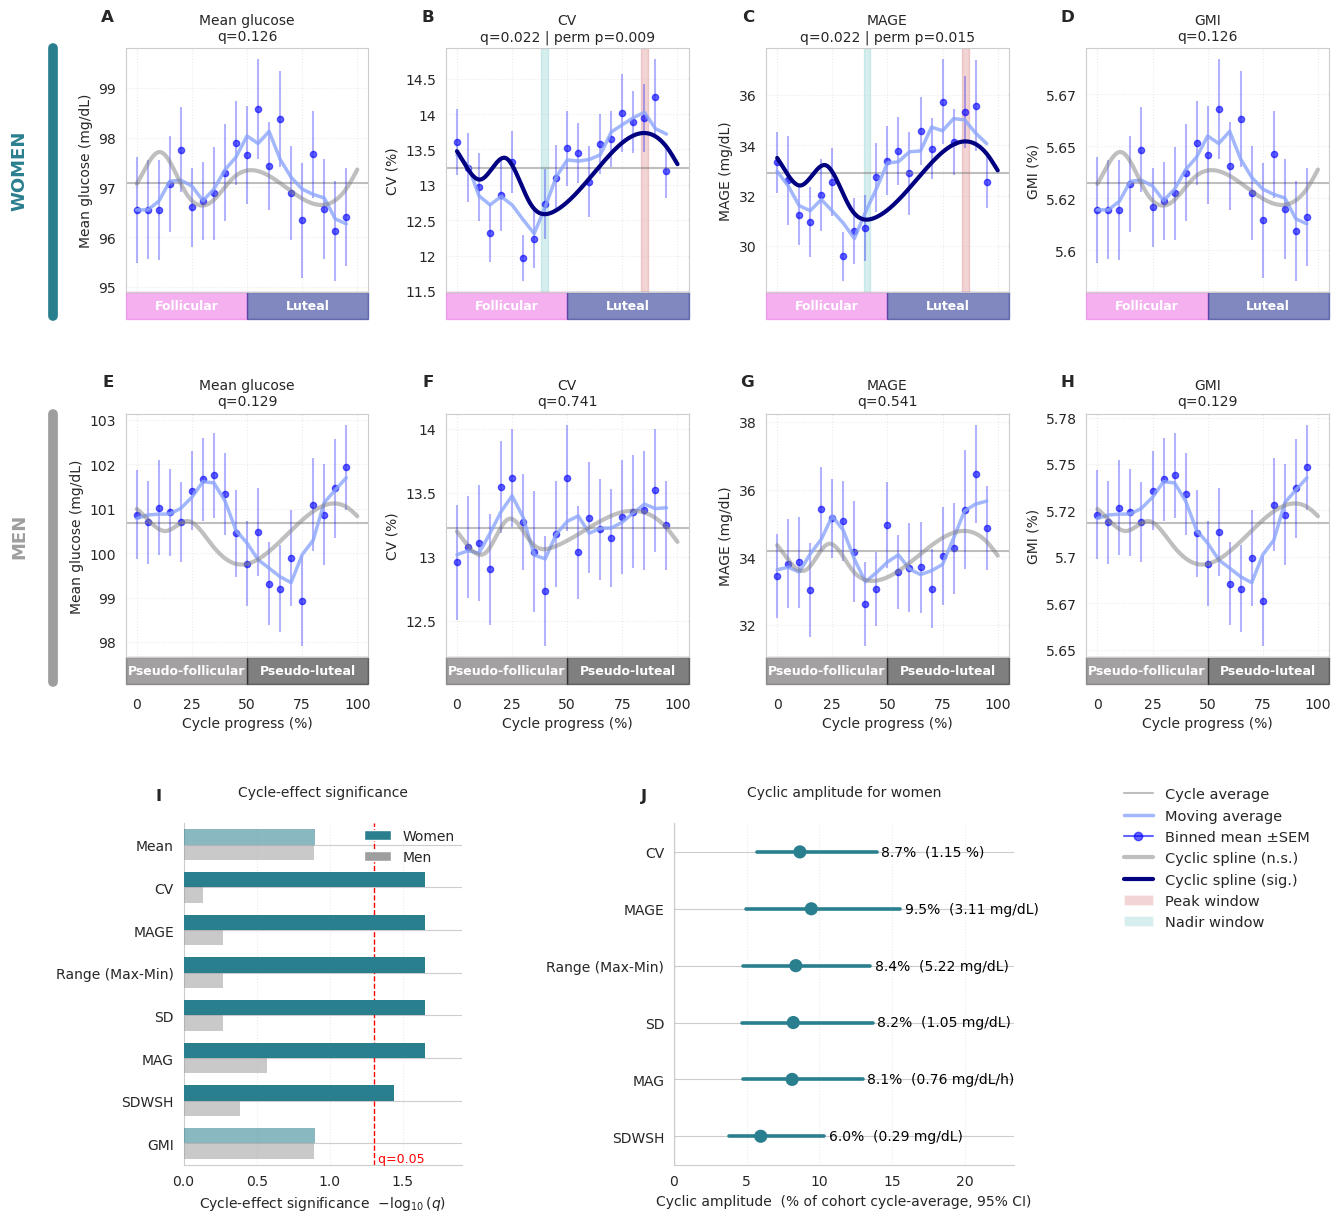

In [7]:
FIGOUT = globals().get('FIGOUT') or os.environ.get('FIGOUT', 'figures'); os.makedirs(FIGOUT, exist_ok=True)   # set in the SETTINGS BOX (top of notebook)

sns.set_style('whitegrid')

METRICS = ['MEAN', 'CV', 'MAGE', 'GMI']
COLS = [('women', 'Women'), ('men', 'Men')]   # columns
UNITS = {'GMI': 'GMI (%)'}  # ensure units even if the CSV label lacks them
COHORT_C = {'women': '#2a7f8f', 'men': '#9e9e9e'}   # rounded group-bar colours
AXLAB = 10   # uniform axis-label font size

def _fmt2(v, _pos=None):
    return f'{v:.2f}'.rstrip('0').rstrip('.')
YFMT = FuncFormatter(_fmt2)

PLOTDATA_CSV = F('iglu_plotdata')   # SETTINGS BOX
PLOT = pd.read_csv(PLOTDATA_CSV) if os.path.exists(PLOTDATA_CSV) else pd.DataFrame()
# Keep the displayed negative control aligned to the prespecified 36-metric family.
# The consolidated plot-data export may retain three obsolete male-only threshold rows.
RESULTS_CSV = F('iglu_results')     # SETTINGS BOX
if not PLOT.empty:
    _primary_metrics = set(PLOT.loc[PLOT['cohort'].eq('women'), 'metric'].unique())
    PLOT = PLOT[~(PLOT['cohort'].eq('men') & ~PLOT['metric'].isin(_primary_metrics))].copy()
    if os.path.exists(RESULTS_CSV):
        _res = pd.read_csv(RESULTS_CSV)
        _male_q = (_res[_res['notebook'].str.startswith('men_iglu_calendar')]
                   .drop_duplicates('metric').set_index('metric')['fdr_p'])
        _is_male = PLOT['cohort'].eq('men')
        PLOT.loc[_is_male, 'p_fdr'] = PLOT.loc[_is_male, 'metric'].map(_male_q)

def _load(cohort, metric):
    if PLOT.empty:
        return PLOT
    return PLOT[(PLOT['cohort'] == cohort) & (PLOT['metric'] == metric)]

def _metric_label(metric):
    for cohort, _ in COLS:
        d = _load(cohort, metric)
        if not d.empty:
            return str(d['label'].iloc[0])
    return metric

_NICE = [1, 2, 2.5, 5]

def _nice_step(vrange, target=4):
    """A 1/2/2.5/5 x 10^k tick step giving ~`target` intervals over `vrange`."""
    if not np.isfinite(vrange) or vrange <= 0:
        return None
    raw = vrange / target
    mag = 10 ** math.floor(math.log10(raw))
    for m in (1, 2, 2.5, 5, 10):
        if raw <= m * mag:
            return m * mag
    return 10 * mag

def _nice_below(step):
    """The next-smaller 1/2/2.5/5 x 10^k step below `step`."""
    exp = math.floor(math.log10(step))
    mant = step / 10 ** exp
    idx = min(range(len(_NICE)), key=lambda i: abs(_NICE[i] - mant))
    return 5 * 10 ** (exp - 1) if idx == 0 else _NICE[idx - 1] * 10 ** exp

def _count_ticks(lo, hi, step):
    """Number of `step` multiples that fall within [lo, hi]."""
    return math.floor(hi / step + 1e-9) - math.ceil(lo / step - 1e-9) + 1

def _pair_step(lims, min_ticks=4, target=4):
    """Largest shared nice step such that every axis in `lims` shows >= min_ticks."""
    step = _nice_step(max(hi - lo for lo, hi in lims), target)
    if step is None:
        return None
    for _ in range(12):
        if all(_count_ticks(lo, hi, step) >= min_ticks for lo, hi in lims):
            break
        step = _nice_below(step)
    return step

def _phase_bar(ax, cohort='women'):
    ax.set_xlim(-5, 105)
    tr = ax.get_xaxis_transform()
    if cohort == 'men':
        c_fol, c_lut = "#474343", "#000000"
        l_fol, l_lut = 'Pseudo-follicular', 'Pseudo-luteal'
        fs = 9          # longer labels -> smaller font so each stays inside its half
    else:
        c_fol, c_lut = '#eb63e0', '#051281'
        l_fol, l_lut = 'Follicular', 'Luteal'
        fs = 9
    ax.fill_between([-5, 50], -0.11, 0, color=c_fol, alpha=0.5, transform=tr, clip_on=False)
    ax.fill_between([50, 105], -0.11, 0, color=c_lut, alpha=0.5, transform=tr, clip_on=False)
    ax.text(22.5, -0.07, l_fol, transform=tr, ha='center', color='white', fontweight='bold', fontsize=fs)
    ax.text(77.5, -0.07, l_lut, transform=tr, ha='center', color='white', fontweight='bold', fontsize=fs)

def _pstr(p):
    return '-' if pd.isna(p) else ('<0.001' if p < 0.001 else f'{p:.3f}')

def draw_trend(ax, cohort, metric, show_xlabel=True, show_ylabel=True):
    d = _load(cohort, metric)
    if d.empty:
        ax.text(0.5, 0.5, f'No data\n{cohort} / {metric}', ha='center', va='center',
                transform=ax.transAxes, color='crimson', fontsize=8)
        ax.set_xticks([]); return
    label = UNITS.get(metric, str(d['label'].iloc[0]))
    b = d[d['series'] == 'binned'].sort_values('x')
    s = d[d['series'] == 'spline'].sort_values('x')
    pfdr, pperm = d['p_fdr'].iloc[0], d['p_perm'].iloc[0]
    amp, alo, ahi = d['amplitude'].iloc[0], d['amp_ci_lo'].iloc[0], d['amp_ci_hi'].iloc[0]
    verdict = str(d['verdict'].iloc[0])
    sig = (pd.notna(pperm) and pperm < 0.05) or (verdict == 'CONFIRMED TREND')
    if len(b):
        ax.axhline(b['y'].mean(), color='gray', lw=1.5, alpha=0.5)
        ax.errorbar(b['x'], b['y'], yerr=b['sem'], fmt='none', ecolor='blue', alpha=0.3)
        ax.scatter(b['x'], b['y'], color='blue', s=20, alpha=0.6)
        ax.plot(b['x'], b['y'].rolling(3, center=True, min_periods=1).mean(),
                color='#8ba5fc', lw=2.5, alpha=0.8)
    if len(s):
        ax.plot(s['x'], s['y'], color='navy' if sig else 'gray', lw=3, alpha=1.0 if sig else 0.5)
        if sig:
            xv, yv = s['x'].values, s['y'].values
            ax.axvspan(xv[yv.argmax()] - 1.5, xv[yv.argmax()] + 1.5, color='#D67173', alpha=0.3, zorder=0)
            ax.axvspan(xv[yv.argmin()] - 1.5, xv[yv.argmin()] + 1.5, color='#78C9C7', alpha=0.3, zorder=0)
    fdr = '<0.001' if (pd.notna(pfdr) and pfdr < 0.001) else (f'{pfdr:.3f}' if pd.notna(pfdr) else '-')
    sub = f'q={fdr}' + (f' | perm p={_pstr(pperm)}' if pd.notna(pperm) else '')
    ax.set_title(label.split(' (')[0] + '\n' + sub, fontsize=10)
    _phase_bar(ax, cohort)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.tick_params(axis='x', pad=25)
    ax.grid(True, linestyle=':', alpha=0.4)
    if show_ylabel:
        ax.set_ylabel(label, fontsize=AXLAB)
    if show_xlabel:
        ax.set_xlabel('Cycle progress (%)', fontsize=AXLAB)
    else:
        ax.tick_params(axis='x', labelbottom=False)

NAVY = '#051281'
LABMAP = {'MEAN': 'Mean', 'CV': 'CV', 'MAGE': 'MAGE', 'RANGE': 'Range (Max-Min)',
          'GMI': 'GMI', 'SD': 'SD', 'MAG': 'MAG', 'SDWSH': 'SDWSH'}
nrows_grid, ncols = len(COLS), len(METRICS)
fig = plt.figure(figsize=(3.2 * ncols, 4.10 * nrows_grid + 4.0))
GAP_GRID, GAP_FOREST = 0.5, 0.35
outer = fig.add_gridspec(2, 1, height_ratios=[4.46 * nrows_grid, 5.0], hspace=GAP_FOREST,
                         left=0.055, right=0.995, top=0.965, bottom=0.05)
top_gs = outer[0].subgridspec(nrows_grid, ncols, hspace=GAP_GRID, wspace=0.32)
axes = [[fig.add_subplot(top_gs[r, c]) for c in range(ncols)] for r in range(nrows_grid)]

for r, (cohort, clabel) in enumerate(COLS):
    for c, metric in enumerate(METRICS):
        draw_trend(axes[r][c], cohort, metric,
                   show_xlabel=(r == nrows_grid - 1), show_ylabel=True)
        axes[r][c].text(-0.05, 1.1, chr(ord('A') + r * ncols + c), transform=axes[r][c].transAxes,
                        fontsize=12, fontweight='bold', va='bottom', ha='right')
    # rounded colour group bar per cohort row (Fig-5 style), full row height + gap to label
    _cbar = COHORT_C[cohort]
    axes[r][0].plot([-0.30, -0.30], [-0.1, 1], transform=axes[r][0].transAxes,
                    color=_cbar, lw=7, solid_capstyle='round', clip_on=False, zorder=5)
    axes[r][0].text(-0.44, 0.5, clabel.upper(), transform=axes[r][0].transAxes, rotation=90,
                    va='center', ha='center', fontsize=13, fontweight='bold', color=_cbar, clip_on=False)

for c in range(ncols):
    lims = [axes[r][c].get_ylim() for r in range(nrows_grid)]
    step = _pair_step(lims, min_ticks=4)
    for r in range(nrows_grid):
        if step:
            axes[r][c].yaxis.set_major_locator(MultipleLocator(step))
        axes[r][c].yaxis.set_major_formatter(YFMT)

fgs = outer[1].subgridspec(1, 4, width_ratios=[-1.5, 2.7, 3.3, 1], wspace=1.5)
axL = fig.add_subplot(fgs[0, 1])   # I (left): significance
axF = fig.add_subplot(fgs[0, 2])   # J (right): amplitude

W_C, M_C = '#2a7f8f', '#9e9e9e'
THRESH = -np.log10(0.05)
SIG_METRICS = ['MEAN', 'CV', 'MAGE', 'RANGE', 'SD', 'MAG', 'SDWSH', 'GMI']
srows = []
for met in SIG_METRICS:
    for coh in ('women', 'men'):
        d = _load(coh, met)
        if d.empty:
            continue
        srows.append(dict(metric=met, cohort=coh, p_fdr=d['p_fdr'].iloc[0]))
S = pd.DataFrame(srows)
S['nlp'] = -np.log10(S['p_fdr'].clip(lower=1e-4))
ys = np.arange(len(SIG_METRICS))[::-1]; hh = 0.36
for kk, met in enumerate(SIG_METRICS):
    for coh, off, col in [('women', +hh / 2, W_C), ('men', -hh / 2, M_C)]:
        rr = S[(S.metric == met) & (S.cohort == coh)]
        if rr.empty:
            continue
        rr = rr.iloc[0]; sig = rr['p_fdr'] < 0.05
        axL.barh(ys[kk] + off, rr['nlp'], height=hh, color=col, alpha=1.0 if sig else 0.55,
                 edgecolor='none', zorder=3)
axL.axvline(THRESH, color='r', ls='--', lw=1, zorder=2)
# -0.5 is the ylim floor set on the next line. This was `len(SIG_METRICS) - 7.5`, which
# only evaluated to the floor while the list had exactly 7 entries.
axL.text(THRESH, -0.5, ' q=0.05', color='r', fontsize=9, va='bottom', ha='left')
axL.set_yticks(ys); axL.set_yticklabels([LABMAP.get(m, m) for m in SIG_METRICS], fontsize=10)
axL.set_xlim(0, max(S['nlp'].max() * 1.15, THRESH * 1.3)); axL.set_ylim(-0.5, len(SIG_METRICS) - 0.5)
axL.set_xlabel(r'Cycle-effect significance  $-\log_{10}(q)$', fontsize=AXLAB)
axL.set_title('Cycle-effect significance', fontsize=10, pad=20)
axL.text(-0.08, 1.06, chr(ord('A') + nrows_grid * ncols), transform=axL.transAxes,
         fontsize=12, fontweight='bold', va='bottom', ha='right')
axL.legend(handles=[Patch(facecolor=W_C, label='Women'), Patch(facecolor=M_C, label='Men')],
           loc='upper right', frameon=False, fontsize=10, bbox_to_anchor=(1.02, 1.02))
axL.grid(True, axis='x', ls=':', alpha=.4); sns.despine(ax=axL)

AMP_METRICS = ['CV', 'MAGE', 'RANGE', 'SD', 'MAG', 'SDWSH']
AMP_UNIT = {'CV': '%', 'MAGE': 'mg/dL', 'RANGE': 'mg/dL', 'SD': 'mg/dL', 'MAG': 'mg/dL/h',
            'SDWSH': 'mg/dL'}
amp_rows = []
for met in AMP_METRICS:
    d = _load('women', met)
    if d.empty or pd.isna(d['amplitude'].iloc[0]):
        continue
    r = d.iloc[0]; gm = d[d['series'] == 'binned']['y'].mean()
    amp_rows.append(dict(metric=met, amp=r['amplitude'], pct=100 * r['amplitude'] / gm,
                         plo=100 * r['amp_ci_lo'] / gm, phi=100 * r['amp_ci_hi'] / gm))
A = pd.DataFrame(amp_rows)
yy = np.arange(len(A))[::-1]
for k, rr in A.iterrows():
    axF.plot([rr['plo'], rr['phi']], [yy[k], yy[k]], color='#2a7f8f', lw=2.6, zorder=2)
    axF.scatter(rr['pct'], yy[k], s=90, color='#2a7f8f', edgecolor='none', zorder=3)
    axF.text(rr['phi'] + 0.3, yy[k],
             f"{rr['pct']:.1f}%  ({rr['amp']:.2f} {AMP_UNIT.get(rr['metric'], 'mg/dL')})",
             va='center', ha='left', fontsize=AXLAB, color='black')
axF.axvline(0, color='k', lw=.8, alpha=.6)
axF.set_yticks(yy); axF.set_yticklabels([LABMAP.get(m, m) for m in A['metric']], fontsize=10)
axF.set_xlim(0, A['phi'].max() * 1.5); axF.set_ylim(-0.5, len(A) - 0.5)
axF.set_xlabel('Cyclic amplitude  (% of cohort cycle-average, 95% CI)', fontsize=AXLAB)
axF.set_title('Cyclic amplitude for women', fontsize=10, pad=20)
axF.text(-0.08, 1.06, chr(ord('A') + nrows_grid * ncols + 1), transform=axF.transAxes,
         fontsize=12, fontweight='bold', va='bottom', ha='right')
axF.grid(True, axis='x', ls=':', alpha=.4); sns.despine(ax=axF)

legend_elems = [
    Line2D([0], [0], color='gray', lw=1.5, alpha=0.5),
    Line2D([0], [0], color='#8ba5fc', lw=2.5, alpha=0.8),
    Line2D([0], [0], marker='o', color='blue', ls='-', markersize=6, alpha=0.6),
    Line2D([0], [0], color='gray', lw=3, alpha=0.5),
    Line2D([0], [0], color='navy', lw=3),
    Patch(facecolor='#D67173', alpha=0.3),
    Patch(facecolor='#78C9C7', alpha=0.3),
]
legend_labels = ['Cycle average', 'Moving average', 'Binned mean ±SEM',
                 'Cyclic spline (n.s.)', 'Cyclic spline (sig.)', 'Peak window', 'Nadir window']
_=fig.legend(legend_elems, legend_labels, loc='upper right', ncol=1,
             frameon=False, fontsize=10.5, bbox_to_anchor=(0.99, 0.37))

os.makedirs('figures', exist_ok=True)
fig.savefig(f'{FIGOUT}/Figure3.png', dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig(f'{FIGOUT}/Figure3.pdf', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

---
## Figures 4 & 5 - PPGR population + within-woman

# Figure 4 & 5 — PPGR × menstrual cycle

**Figure 4 (population phenomenon)** and **Figure 5 (within-woman confirmation)**, unified on one currency: *Luteal − Follicular step (% of follicular mean)*.

Both figures are plot-only. Figure 4 reads the saved model results in the meal-level store (`data/restricted/fig4_meals.pkl`, restricted) and the CV summaries (`data/fig4_hourly_cv.csv`, `data/restricted/fig4_day_night_cv.csv`, restricted); Figure 5 reads `data/fig5_grids.csv` and the per-woman paired results (`data/restricted/fig5_deltas.csv`, `data/restricted/fig5_paired.csv`, restricted).

In [8]:
FIGOUT = globals().get('FIGOUT') or os.environ.get('FIGOUT', 'figures'); os.makedirs(FIGOUT, exist_ok=True)   # set in the SETTINGS BOX (top of notebook)

sns.set_style('whitegrid'); np.random.seed(42)
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'figure.dpi': 120, 'savefig.dpi': 300, 'axes.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
})
FOLL, LUT = '#eb63e0', '#051281'          # Follicular=pink, Luteal=navy (FIXED)
SUBJ = L.SUBJ
os.makedirs('figures', exist_ok=True)

YLABEL_MAP = {
    'peak_rise': 'Peak Rise (mg/dL)', 'descent_rate': 'Descent Rate (mg/dL/min)',
    'true_iAUC': 'iAUC (mg/dL×h)', 'nadir_dip': 'Nadir dip (mg/dL)',
    'peak_time': 'Time-to-peak (min)', 'baseline_glucose': 'Baseline (mg/dL)',
}
def pstars(p):
    try: p = float(p)
    except Exception: return ''
    if not np.isfinite(p): return ''
    return '***' if p < .001 else '**' if p < .01 else '*' if p < .05 else 'ns'
def savefig(name):
    for ext in ('pdf', 'png'):
        plt.savefig(f'{FIGOUT}/{name}.{ext}', dpi=300, bbox_inches='tight', facecolor='white')
    print(f'saved figures/{name}.pdf + .png')
_fd = lambda v: f'{v:+.3f}' if abs(v) < 1 else f'{v:+.1f}'

# ---- within-woman paired engine ----
def assign_phase(m, buffer):
    if buffer <= 0:
        return m[m['phase'].isin(['Follicular', 'Luteal'])].copy()
    d = m.copy(); ov = d['menstrual_cycle_cal'] - 14; day = d['cycle_day_record']
    foll = (day >= buffer) & (day <= ov - buffer)
    lut  = (day >= ov + buffer) & (day <= d['menstrual_cycle_cal'] - buffer)
    d['phase'] = np.select([foll, lut], ['Follicular', 'Luteal'], default=None)
    return d[d['phase'].isin(['Follicular', 'Luteal'])].copy()
MEAL_WINDOWS = {'breakfast': (5, 11), 'lunch': (12, 15), 'dinner': (17, 21)}  # LOCAL clock (Israel, DST-aware); breakfast=first meal 05-11h local
def add_mealtime(d):
    dt = pd.to_datetime(d['meal_datetime']); d = d.copy()  # already Israel local wall-clock
    d['meal_hour'] = dt.dt.hour + dt.dt.minute / 60; d['_date'] = dt.dt.date
    d['is_first_meal'] = d.groupby([SUBJ, '_date'])['meal_hour'].transform('min').eq(d['meal_hour'])
    return d.drop(columns='_date')
def window_filter(d, which):
    if which == 'all': return d
    lo, hi = MEAL_WINDOWS[which]; sel = (d['meal_hour'] >= lo) & (d['meal_hour'] < hi)
    if which == 'breakfast': sel = sel & d['is_first_meal']
    return d[sel]
def signflip_p(d, alternative='greater', B=20000, seed=0):
    d = np.asarray(d, float); d = d[~np.isnan(d)]; n = len(d)
    if n == 0: return np.nan
    obs = d.mean(); rng = np.random.default_rng(seed)
    null = (rng.choice([-1.0, 1.0], size=(B, n)) * d).mean(axis=1)
    if alternative == 'greater': return (1 + np.sum(null >= obs)) / (B + 1)
    if alternative == 'less': return (1 + np.sum(null <= obs)) / (B + 1)
    return (1 + np.sum(np.abs(null) >= abs(obs))) / (B + 1)
def boot_ci(d, B=10000, seed=1, alpha=0.05):
    d = np.asarray(d, float); d = d[~np.isnan(d)]; n = len(d)
    if n == 0: return (np.nan, np.nan)
    rng = np.random.default_rng(seed); bs = d[rng.integers(0, n, size=(B, n))].mean(axis=1)
    return tuple(np.percentile(bs, [100 * alpha / 2, 100 * (1 - alpha / 2)]))
def carb_bins(d, n=3):
    q = d['meal_carbs'].quantile(np.linspace(0, 1, n + 1)).values; edges = np.unique(np.round(q, 1))
    return pd.cut(d['meal_carbs'], edges, labels=[f'q{i+1}' for i in range(len(edges) - 1)], include_lowest=True)
def macro_key(d, cols, nbins):
    s = None
    for c in cols:
        b = pd.qcut(d[c], nbins, labels=False, duplicates='drop').astype('Int64').astype(str)
        s = b if s is None else s.str.cat(b, sep='|')
    return s.where(~d[cols].isna().any(axis=1), other=np.nan)
def matched_deltas(d, key, ycol, responders_only=True):
    x = d.dropna(subset=[ycol, key, 'phase']).copy()
    if responders_only: x = x[x['is_responder']]
    cell = x.groupby([SUBJ, key, 'phase'], observed=True)[ycol].mean().unstack().dropna(subset=['Follicular', 'Luteal'])
    cell = cell.assign(_d=cell['Luteal'] - cell['Follicular'])
    return cell.groupby(level=SUBJ)['_d'].mean().values
def matched_foll_ref(d, key, ycol, responders_only=True):
    x = d.dropna(subset=[ycol, key, 'phase']).copy()
    if responders_only: x = x[x['is_responder']]
    cell = x.groupby([SUBJ, key, 'phase'], observed=True)[ycol].mean().unstack().dropna(subset=['Follicular', 'Luteal'])
    return float(cell.groupby(level=SUBJ)['Follicular'].mean().mean())
print('helpers + within-woman engine loaded')

helpers + within-woman engine loaded


## Data — population (meal-level store) + within-woman (paired results)

In [9]:
# ---- Fig 4 population objects: loaded from the meal-level store ----
_S = pickle.load(open(F('fig4_store'), 'rb'))   # SETTINGS BOX
RESP = _S['RESP']; binary = _S['binary']; mt_grid = _S['mt']   # (Fig5 later reuses the name 'mt' for paired data)
mt_spline = _S['mt_spline']; spline = _S['spline']; sig_mt = _S['sig_mt']
data = {'CURVES': _S['CURVES']}
print(f"[Fig4] RESP={len(RESP):,} women={RESP[SUBJ].nunique()} | "
      f"survivors={sig_mt}")

# ---- Fig 5 within-woman objects: loaded from the paired-results CSVs ----
fig5_grids = pd.read_csv(F('fig5_grids'))     # SETTINGS BOX
fig5_deltas = pd.read_csv(F('fig5_deltas'))  # SETTINGS BOX
print(f"[Fig5] {len(fig5_grids)} grid rows, {len(fig5_deltas)} deltas")

[Fig4] RESP=3,815 women=209 | survivors=[('breakfast', 'descent_rate'), ('breakfast', 'peak_rise')]
[Fig5] 49 grid rows, 228 deltas


## Figure 4 statistics — loaded from the meal-level store

In [10]:
# Fig 4 is PLOT-ONLY: all population calc (binary step, meal-time binary + cyclic grids, splines,
# baseline control) was computed upstream and is loaded from the meal-level store (prior cell).
WINDOWS = ['breakfast', 'lunch', 'dinner']
print(binary[['metric', 'pct', 'p_fdr']].round(3).to_string(index=False))
print('survivors (cc-FDR+perm):', sig_mt)

          metric    pct  p_fdr
    descent_rate 11.514  0.015
       peak_rise  4.057  0.187
       true_iAUC  5.317  0.187
       peak_time  2.926  0.337
baseline_glucose -0.172  0.716
survivors (cc-FDR+perm): [('breakfast', 'descent_rate'), ('breakfast', 'peak_rise')]


## Figure 4 - the phenomenon

**A** within-hour CV across the day by phase * **B** within-hour CV in daytime vs overnight by phase (descriptive, mean ± SEM) * **C** mean postprandial curve (same baseline, larger luteal excursion) * **D** effect-size forest (GLMM % step, all outcomes) * **E** meal-time localization heatmap * **F**, **G** breakfast descent-rate and peak-rise cyclic-spline fits.

saved figures/Figure4.pdf + .png


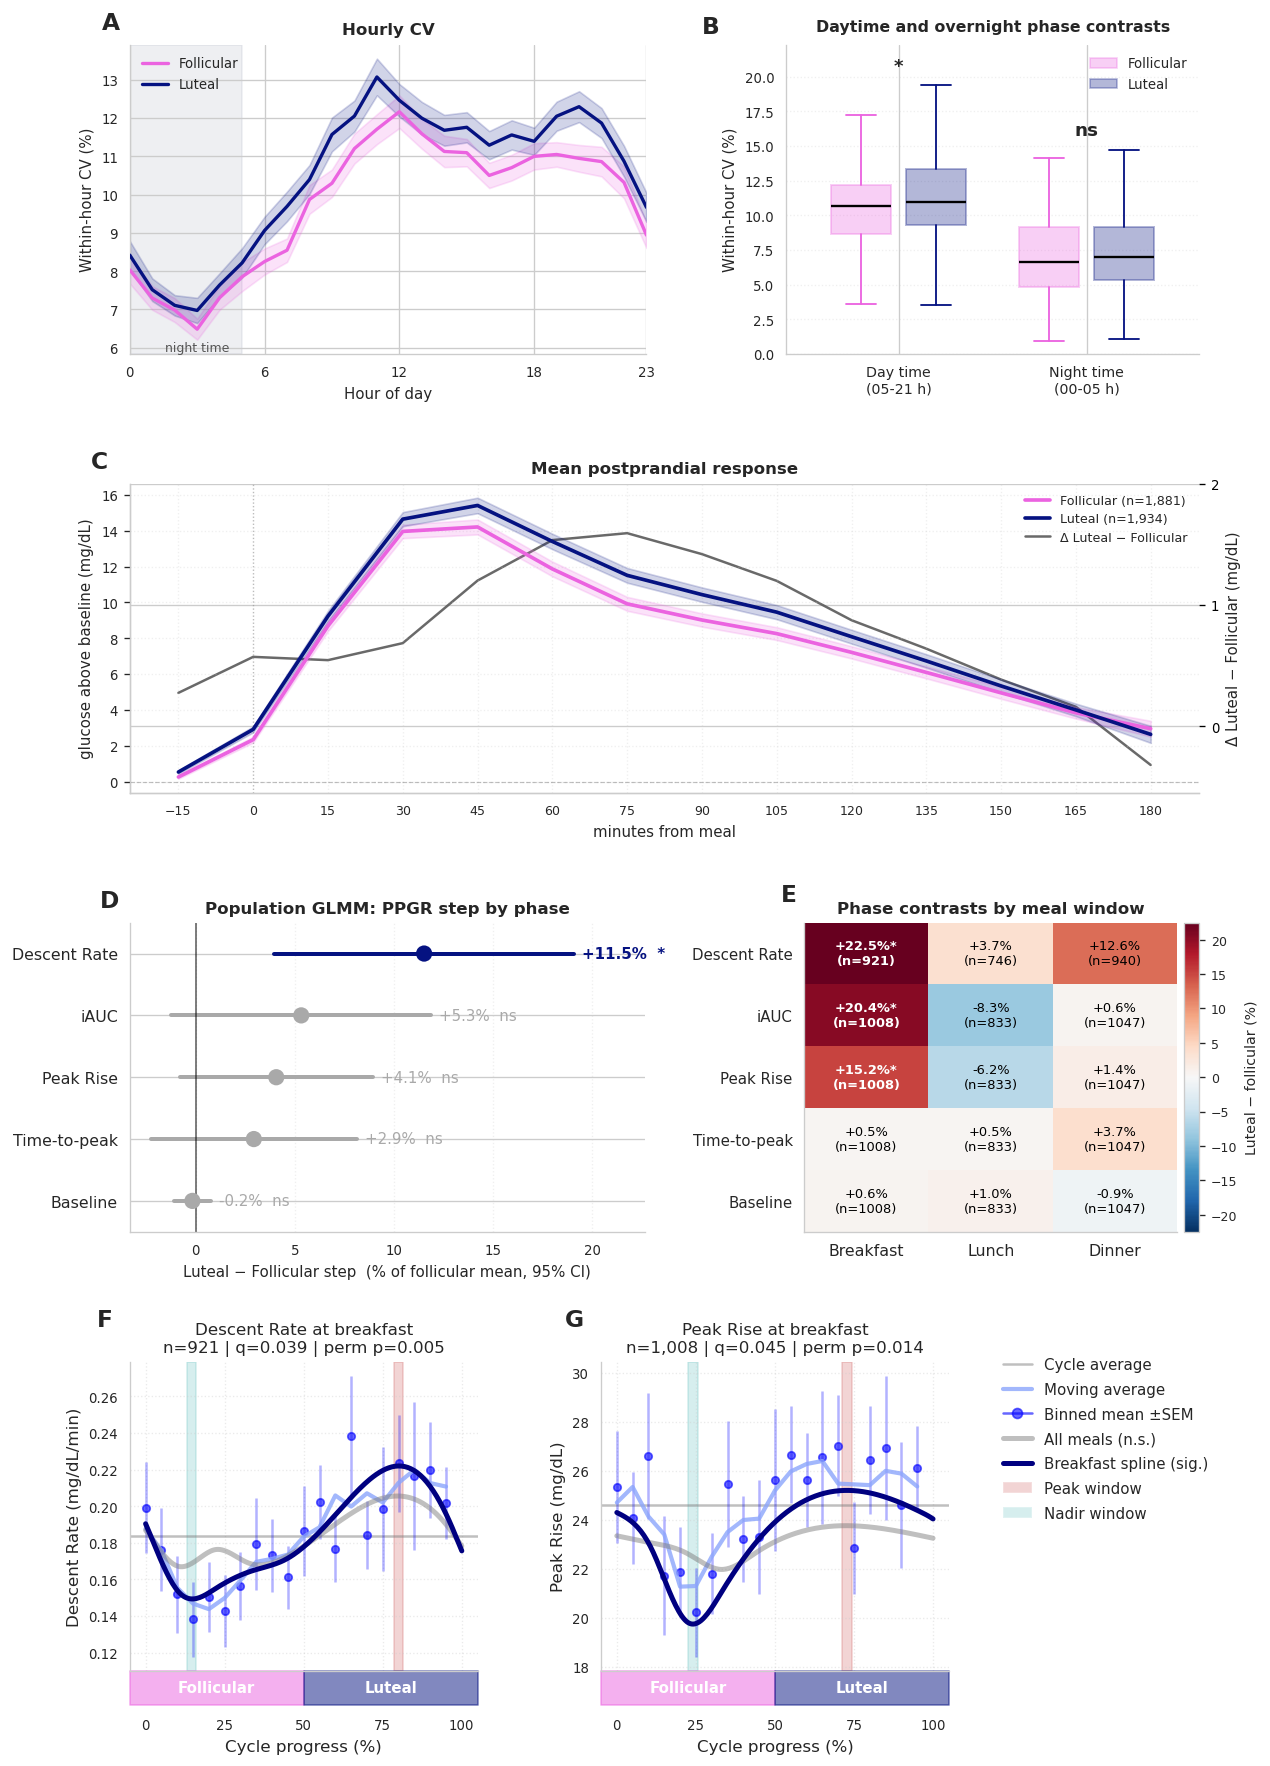

In [11]:
# ================= FIGURE 4 — POPULATION PHENOMENON =================
# Panel order: A within-hour CV | B day/night variability
#              C mean postprandial curve (full width)
#              D effect-size forest | E meal-time heatmap
#              F breakfast descent-rate cycle | G breakfast peak-rise cycle
# (Anatomy schematic pulled out to its own solo figure -> next cell.)
fo = binary.sort_values('pct').reset_index(drop=True)
fig = plt.figure(figsize=(11.5, 17.6))
gs = fig.add_gridspec(4, 1, height_ratios=[1.0, 1.0, 1.0, 1.0], hspace=0.42)
gsR1 = gs[0].subgridspec(1, 2, width_ratios=[1.25, 1.0], wspace=0.30)   # A CV | B day/night
gsR2 = gs[1].subgridspec(1, 1)                                          # C curve (full width)
gsR3 = gs[2].subgridspec(1, 2, width_ratios=[1.5, 1.15], wspace=0.35)   # D forest | E heatmap
gsR4 = gs[3].subgridspec(1, 3, width_ratios=[1.15, 1.15, 0.42], wspace=0.45)   # F | G | shared key
axCV  = fig.add_subplot(gsR1[0])   # within-hour CV      -> panel A
axDN  = fig.add_subplot(gsR1[1])   # day/night phase gap -> panel B
axC   = fig.add_subplot(gsR2[0])   # mean curve          -> panel C
axF   = fig.add_subplot(gsR3[0])   # forest              -> panel D
axH   = fig.add_subplot(gsR3[1])   # heatmap             -> panel E
axS1  = fig.add_subplot(gsR4[0])   # breakfast descent_rate spline -> panel F
axS2  = fig.add_subplot(gsR4[1])   # breakfast peak_rise spline    -> panel G
axSL  = fig.add_subplot(gsR4[2])   # shared key for F/G (no data)

# --- A within-hour CV (%) across the day by phase: luteal excess variability is daytime (fed) ---
NSC = '#9aa0b4'
_loc = pd.read_csv(F('sleep_loc'))          # SETTINGS BOX
_lcv = _loc[_loc['metric'] == 'within_hour_cv']
axCV.axvspan(0, 5, color=NSC, alpha=0.16, zorder=0)                             # sleep window (00-06)
for _ph, _col in [('Follicular', FOLL), ('Luteal', LUT)]:
    _dph = _lcv[_lcv['phase'] == _ph].sort_values('hour')
    axCV.plot(_dph['hour'], _dph['val'], color=_col, lw=2, label=_ph, zorder=3)
    axCV.fill_between(_dph['hour'], _dph['val'] - _dph['sem'], _dph['val'] + _dph['sem'], color=_col, alpha=0.18, zorder=2)
axCV.set_xlim(0, 23); axCV.set_xticks([0, 6, 12, 18, 23])
axCV.set_xlabel('Hour of day', fontsize=9); axCV.set_ylabel('Within-hour CV (%)', fontsize=9)
axCV.set_title('Hourly CV', fontsize=10, weight='bold')
axCV.text(3, axCV.get_ylim()[0], 'night time', ha='center', va='bottom', fontsize=7.5, color='#555')
axCV.legend(frameon=False, loc='upper left', fontsize=8)
axCV.text(-0.02, 1.05, 'A', transform=axCV.transAxes, fontsize=14, fontweight='bold', ha='right')
sns.despine(ax=axCV)

# --- B within-hour CV by phase, daytime vs sleep (box = per-woman distribution; population mixed model) ---
# motivation for the meal-level PPGR analysis: the variability we saw sits in fed (daytime) hours.
# TEST = population LMM  cv ~ phase*window + (1|woman)  on hourly obs (not paired subject means)
_sub = pd.read_csv(F('sleep_cv'))                                   # per-woman phase x window mean CV
_sub['subj'] = _sub[SUBJ].astype(str)
# population LMM on woman-cell means (one value per woman x phase x window) -> avoids hourly
# pseudoreplication; phase is a per-day label so hourly rows are not independent for this contrast
_mm = {}
for _ref in ('Day', 'Night'):                                                        # refit per ref -> read each window's phase contrast
    _fit = smf.mixedlm(f"cv ~ C(phase, Treatment('Follicular'))*C(window, Treatment('{_ref}'))",
                       _sub, groups=_sub['subj']).fit(reml=False)
    _pc = [k for k in _fit.params.index if 'phase' in k and 'window' not in k][0]
    _mm[_ref] = (float(_fit.params[_pc]), float(_fit.pvalues[_pc]))
_wins = ['Day', 'Night']; _wlab = ['Day time\n(05-21 h)', 'Night time\n(00-05 h)']
_off, _bxw = 0.20, 0.32
def _whisk(v):                                              # matplotlib whisker extents (1.5*IQR rule)
    q1, q3 = np.percentile(v, [25, 75]); iqr = q3 - q1
    return v[v >= q1 - 1.5 * iqr].min(), v[v <= q3 + 1.5 * iqr].max()
_wtops = []                                                 # per-window upper-whisker (for asterisk + ylim)
_wlo = np.inf
for _wi, _w in enumerate(_wins):
    _uw = []
    for _k, (_ph, _col) in enumerate([('Follicular', FOLL), ('Luteal', LUT)]):
        _v = _sub[(_sub['window'] == _w) & (_sub['phase'] == _ph)]['cv'].dropna().values
        _pos = _wi + (-_off if _k == 0 else _off)
        axDN.boxplot([_v], positions=[_pos], widths=_bxw, patch_artist=True, showfliers=False,
                     medianprops=dict(color='black', lw=1.4),
                     boxprops=dict(facecolor=_col, alpha=0.30, edgecolor=_col, lw=1.2),
                     whiskerprops=dict(color=_col, lw=1.1), capprops=dict(color=_col, lw=1.1))
        _lo, _hi = _whisk(_v); _uw.append(_hi); _wlo = min(_wlo, _lo)
    _wtops.append(max(_uw))
_span = max(_wtops) - _wlo
for _wi, _w in enumerate(_wins):                            # asterisks just above each window's tallest whisker
    _pv = _mm[_w][1]
    axDN.text(_wi, _wtops[_wi] + _span * 0.04, pstars(_pv),
              ha='center', va='bottom', fontsize=11, fontweight='bold')
axDN.set_xticks(range(len(_wins))); axDN.set_xticklabels(_wlab, fontsize=8.5); axDN.set_xlim(-0.6, 1.6)
axDN.set_ylim(max(0, _wlo - _span * 0.06), max(_wtops) + _span * 0.16)   # headroom so whiskers/CI + stars are not clipped
axDN.set_ylabel('Within-hour CV (%)', fontsize=9)
axDN.set_title('Daytime and overnight phase contrasts', fontsize=9.5, weight='bold', pad=8)
axDN.legend(handles=[Patch(facecolor=FOLL, alpha=0.30, edgecolor=FOLL, label='Follicular'),
                     Patch(facecolor=LUT, alpha=0.30, edgecolor=LUT, label='Luteal')],
            frameon=False, fontsize=8, loc='upper right')
axDN.text(-0.16, 1.02, 'B', transform=axDN.transAxes, fontsize=14, fontweight='bold', ha='right', va='bottom')
axDN.grid(True, axis='y', ls=':', alpha=.3); sns.despine(ax=axDN)

# --- A mean postprandial curve + Delta twin-axis ---
_cv = data['CURVES'].dropna(subset=['minutes_from_meal', 'glucose_from_baseline', 'phase']).copy()
_cv['meal_datetime'] = pd.to_datetime(_cv['meal_datetime'])
_key = RESP[[SUBJ, 'meal_datetime']].copy(); _key['meal_datetime'] = pd.to_datetime(_key['meal_datetime'])
_cv = _cv.merge(_key.drop_duplicates(), on=[SUBJ, 'meal_datetime'], how='inner')   # analyzed set
BIN, WIN = 15, (-15, 180)
_cv = _cv[(_cv['minutes_from_meal'] >= WIN[0]) & (_cv['minutes_from_meal'] <= WIN[1])]
_cv['tbin'] = (_cv['minutes_from_meal'] / BIN).round() * BIN
_pm = {}
for phase, color in [('Follicular', FOLL), ('Luteal', LUT)]:
    dph = _cv[_cv['phase'] == phase]
    g = dph.groupby('tbin')['glucose_from_baseline'].agg(['mean', 'sem']).reset_index()
    n_m = dph.groupby([SUBJ, 'meal_datetime']).ngroups
    axC.plot(g['tbin'], g['mean'], color=color, lw=2.2, label=f'{phase} (n={n_m:,})', zorder=3)
    axC.fill_between(g['tbin'], g['mean'] - g['sem'], g['mean'] + g['sem'], color=color, alpha=.18, zorder=2)
    _pm[phase] = g.set_index('tbin')['mean']
axC.axhline(0, color='gray', ls='--', lw=0.7, alpha=.5); axC.axvline(0, color='#888', ls=':', lw=0.8, alpha=.5)
# Delta = Luteal - Follicular on a secondary axis scaled to its own range (see note below)
_delta = (_pm['Luteal'] - _pm['Follicular']).dropna().sort_index()
axCd = axC.twinx()
_dl, = axCd.plot(_delta.index, _delta.values, color='0.35', ls='-', lw=1.5, alpha=.9,
                 zorder=1, label='Δ Luteal − Follicular')
axCd.set_ylabel('Δ Luteal − Follicular (mg/dL)', fontsize=9)
axCd.tick_params(axis='y', labelsize=plt.rcParams['ytick.labelsize'], colors='black')
axCd.spines['top'].set_visible(False); axCd.spines['right'].set_color('0.55')
_dmin = min(float(_delta.min()), 0.0); _dmax = max(float(_delta.max()), 0.0)
# Delta axis is scaled to the Delta trace itself and is NOT zero-aligned to the glucose axis.
# Alignment used to set the range, and it cost the panel: glucose is almost entirely positive
# (only ~3% of that axis sits below zero) while Delta dips to -0.51, so holding the two zeros
# level pushed the Delta axis up to +16.6 for a trace peaking at 1.59 -- ~90% of the axis was
# empty and the trace read as a flat line. The right-hand ticks carry the Delta zero instead.
_rlo = _dmin - (_dmax - _dmin) * 0.12
_rhi = float(np.ceil(_dmax / 0.5) * 0.5)   # top rounded up to the next 0.5 -> 2.0 (Delta peaks at 1.59)
axCd.set_ylim(_rlo, _rhi)
axCd.yaxis.set_major_locator(MaxNLocator(nbins=5, steps=[1, 2, 2.5, 5, 10]))   # nice ticks: 0, 0.5, 1, 1.5, 2
axC.set_zorder(axCd.get_zorder() + 1); axC.patch.set_visible(False)   # phase lines on top
axC.set_xlabel('minutes from meal', fontsize=9); axC.set_ylabel('glucose above baseline (mg/dL)', fontsize=9)
axC.set_xticks(np.arange(-15, 181, 15)); axC.tick_params(axis='x', labelsize=7.5)   # 15-min CGM grid
axC.set_title('Mean postprandial response', fontsize=10, weight='bold')
_h1, _l1h = axC.get_legend_handles_labels()
axC.legend(_h1 + [_dl], _l1h + ['Δ Luteal − Follicular'], fontsize=7.6, frameon=False, loc='upper right')
axC.text(-0.02, 1.05, 'C', transform=axC.transAxes, fontsize=14, fontweight='bold', ha='right')
axC.grid(True, ls=':', alpha=.3); sns.despine(ax=axC)

# --- D forest (GLMM % step, all metrics) ---
for i, r in fo.iterrows():
    sig = r['p_fdr'] < 0.05; c = LUT if sig else '#a9a9a9'
    lo, hi = r['pct'] - 1.96 * r['se_pct'], r['pct'] + 1.96 * r['se_pct']
    axF.plot([lo, hi], [i, i], color=c, lw=2.4, zorder=2)
    axF.scatter(r['pct'], i, s=95, color=c, edgecolor='none', zorder=3)
    axF.text(hi + 0.4, i, f"{r['pct']:+.1f}%  {pstars(r['p_fdr'])}", va='center', fontsize=9,
             color=c, fontweight='bold' if sig else 'normal')
axF.axvline(0, color='k', lw=1, alpha=.6); axF.set_yticks(range(len(fo))); axF.set_ylim(-0.5, len(fo) - 0.5)
axF.set_xlim(right=axF.get_xlim()[1] + 2.5)   # room for % + stars labels
axF.set_yticklabels([YLABEL_MAP.get(mm, mm).split(' (')[0] for mm in fo['metric']], fontsize=9.5)
axF.set_xlabel('Luteal − Follicular step  (% of follicular mean, 95% CI)', fontsize=9)
axF.set_title('Population GLMM: PPGR step by phase', fontsize=10, weight='bold')
axF.text(-0.02, 1.05, 'D', transform=axF.transAxes, fontsize=14, fontweight='bold', ha='right')
axF.grid(True, axis='x', ls=':', alpha=.3); sns.despine(ax=axF)

# --- E meal-time heatmap ---
# Row order = panel D's forest order, so D and E read as one block. baseline_glucose IS in the
# grid (the control is fitted per meal window), so it now
# appears here as it does in D. The filter stays: a metric with no meal-window row would
# otherwise open a blank row and a gap above the x-axis.
mets = [m for m in fo['metric'].tolist() if m in set(mt_grid['metric'])]
M = np.full((len(mets), len(WINDOWS)), np.nan); Fm = np.full((len(mets), len(WINDOWS)), np.nan); Nm = np.zeros((len(mets), len(WINDOWS)), int)
for i, mm in enumerate(mets):
    for j, w in enumerate(WINDOWS):
        rr = mt_grid[(mt_grid['meal'] == w) & (mt_grid['metric'] == mm)]
        if len(rr):
            M[i, j] = float(rr['binary_pct'].iloc[0]); Fm[i, j] = float(rr['binary_fdr'].iloc[0])
            _nn = rr['n'].iloc[0]
            if not np.isfinite(_nn): _nn = rr['n_binary'].iloc[0]   # control: binary fit, no cyclic fit
            Nm[i, j] = int(_nn)
vmax = np.nanmax(np.abs(M)) if np.isfinite(M).any() else 1
im = axH.imshow(M, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto', origin='lower')  # match forest row order
for i in range(len(mets)):
    for j in range(len(WINDOWS)):
        if np.isfinite(M[i, j]):
            st = pstars(Fm[i, j]); st = '' if st == 'ns' else st
            axH.text(j, i, f"{M[i, j]:+.1f}%{st}\n(n={Nm[i, j]})", ha='center', va='center', fontsize=7.8,
                     color='white' if abs(M[i, j]) > 0.6 * vmax else 'black',
                     fontweight='bold' if (np.isfinite(Fm[i, j]) and Fm[i, j] < 0.05) else 'normal')
axH.set_xticks(range(len(WINDOWS))); axH.set_xticklabels([w.capitalize() for w in WINDOWS], fontsize=9.5)
axH.set_yticks(range(len(mets))); axH.set_yticklabels([YLABEL_MAP.get(m, m).split(' (')[0] for m in mets], fontsize=9)
axH.grid(False); axH.set_title('Phase contrasts by meal window', fontsize=10, weight='bold')
axH.text(-0.02, 1.07, 'E', transform=axH.transAxes, fontsize=14, fontweight='bold', ha='right')
cax = make_axes_locatable(axH).append_axes('right', size='4%', pad=0.06)
cb = fig.colorbar(im, cax=cax); cb.set_label('Luteal − follicular (%)', fontsize=8.5); cb.ax.tick_params(labelsize=7.5)

# --- F/G breakfast cyclic splines, drawn in the FIGURE-3 trend grammar ---

AXLAB4 = 10

def _phase_bar4(ax):
    """Figure-3 `_phase_bar`, women branch (identical geometry, colours and font size)."""
    ax.set_xlim(-5, 105); tr = ax.get_xaxis_transform()
    ax.fill_between([-5, 50], -0.11, 0, color=FOLL, alpha=0.5, transform=tr, clip_on=False)
    ax.fill_between([50, 105], -0.11, 0, color=LUT, alpha=0.5, transform=tr, clip_on=False)
    ax.text(22.5, -0.07, 'Follicular', transform=tr, ha='center', color='white',
            fontweight='bold', fontsize=9)
    ax.text(77.5, -0.07, 'Luteal', transform=tr, ha='center', color='white',
            fontweight='bold', fontsize=9)

def _pstr4(p):
    """Figure-3 `_pstr`, tolerant of None as well as NaN."""
    try: p = float(p)
    except (TypeError, ValueError): return '-'
    return '-' if not np.isfinite(p) else ('<0.001' if p < 0.001 else f'{p:.3f}')

def draw_cycle_panel(ax, window, metric):
    """One Figure-3-style cycle panel for a Fig-4 meal-window x metric stratum."""
    cc  = mt_spline.get((window, metric), {})
    gen = spline.get(metric, {})
    b = L.binned_means(L.select_meal_time(RESP, window).dropna(subset=[metric]), metric)
    if len(b):
        ax.axhline(b['mean'].mean(), color='gray', lw=1.5, alpha=0.5, zorder=1)
        ax.errorbar(b['bin'], b['mean'], yerr=b['sem'], fmt='none', ecolor='blue',
                    alpha=0.3, zorder=2)
        ax.scatter(b['bin'], b['mean'], color='blue', s=20, alpha=0.6, zorder=3)
        ax.plot(b['bin'], b['smooth'], color='#8ba5fc', lw=2.5, alpha=0.8, zorder=4)
    if gen.get('pred_y') is not None:                    # all-meals fit = the n.s. reference
        ax.plot(gen['pred_x'], gen['pred_y'], color='gray', lw=3, alpha=0.5, zorder=5)
    if cc.get('pred_y') is not None:
        xv, yv = np.asarray(cc['pred_x'], float), np.asarray(cc['pred_y'], float)
        ax.plot(xv, yv, color='navy', lw=3, zorder=6)
        ax.axvspan(xv[yv.argmax()] - 1.5, xv[yv.argmax()] + 1.5, color='#D67173', alpha=0.3, zorder=0)
        ax.axvspan(xv[yv.argmin()] - 1.5, xv[yv.argmin()] + 1.5, color='#78C9C7', alpha=0.3, zorder=0)
    _qq = mt_grid.loc[(mt_grid['meal'] == window) & (mt_grid['metric'] == metric), 'cc_fdr']
    _lab = YLABEL_MAP.get(metric, metric)
    ax.set_title(f"{_lab.split(' (')[0]} at {window}\n"
                 f"n={cc.get('n', 0):,} | q={_pstr4(_qq.iloc[0] if len(_qq) else None)} | "
                 f"perm p={_pstr4(cc.get('p_spec'))}", fontsize=10)
    _phase_bar4(ax)
    ax.set_xticks([0, 25, 50, 75, 100]); ax.tick_params(axis='x', pad=25)
    ax.set_ylabel(_lab, fontsize=AXLAB4); ax.set_xlabel('Cycle progress (%)', fontsize=AXLAB4)
    ax.grid(True, ls=':', alpha=0.4)

_SPL_AXES = [(axS1, 'F'), (axS2, 'G')]
if len(sig_mt) != len(_SPL_AXES):
    print(f'WARNING sig_mt has {len(sig_mt)} strata, not {len(_SPL_AXES)} -- '
          f'row 4 draws {min(len(sig_mt), len(_SPL_AXES))} panel(s) and blanks the rest: {sig_mt}')
for (_ax, _plab), _stratum in zip(_SPL_AXES, list(sig_mt) + [None] * len(_SPL_AXES)):
    if _stratum is None:
        _ax.axis('off'); continue
    draw_cycle_panel(_ax, *_stratum)
    _ax.text(-0.05, 1.1, _plab, transform=_ax.transAxes, fontsize=14, fontweight='bold',
             va='bottom', ha='right')

# shared key for row 4 -- same entries and order as the Figure-3 figure legend
axSL.axis('off')
axSL.legend(handles=[Line2D([0], [0], color='gray', lw=1.5, alpha=0.5),
                     Line2D([0], [0], color='#8ba5fc', lw=2.5, alpha=0.8),
                     Line2D([0], [0], marker='o', color='blue', ls='-', markersize=6, alpha=0.6),
                     Line2D([0], [0], color='gray', lw=3, alpha=0.5),
                     Line2D([0], [0], color='navy', lw=3),
                     Patch(facecolor='#D67173', alpha=0.3),
                     Patch(facecolor='#78C9C7', alpha=0.3)],
            labels=['Cycle average', 'Moving average', 'Binned mean ±SEM',
                    'All meals (n.s.)', 'Breakfast spline (sig.)', 'Peak window', 'Nadir window'],
            loc='center left', frameon=False, fontsize=9, handlelength=1.9, labelspacing=0.65,
            bbox_to_anchor=(-0.65, 0.75))

savefig('Figure4'); plt.show()

## Figure 5 — within-woman confirmation

**A** one heatmap, one row per nutrition-matching rule ordered simplest to strictest
(carbohydrate, total calories, carbohydrate x protein x fat = primary): left block = within-woman
L-F PPGR step, right block = meal-composition balance; colour = L-F step (% of follicular),
significance by * / bold (composition cells carry no *, i.e. matched). Rows above the line =
breakfast rules; below = all-meal sensitivity. **B-C** per-woman paired phase distributions
(primary rule) below A — B iAUC, C Peak Rise, D Descent Rate (box per phase + per-woman lines).

### How the within-woman matching works (schematic)

We only compare a woman's **luteal** meals with her **follicular** meals when the meals were
**nutritionally similar** — otherwise a difference could just mean she ate something different.

To do that we **split each nutrient into "low" vs "high"**: low/high carbs, low/high protein,
low/high fat. Combining the three splits gives 2 × 2 × 2 = **8 meal types** (for example
"high-carb, low-protein, low-fat"). Luteal and follicular meals are compared **only within the
same meal type**; those differences are then averaged.

saved figures/Figure5.pdf + .png


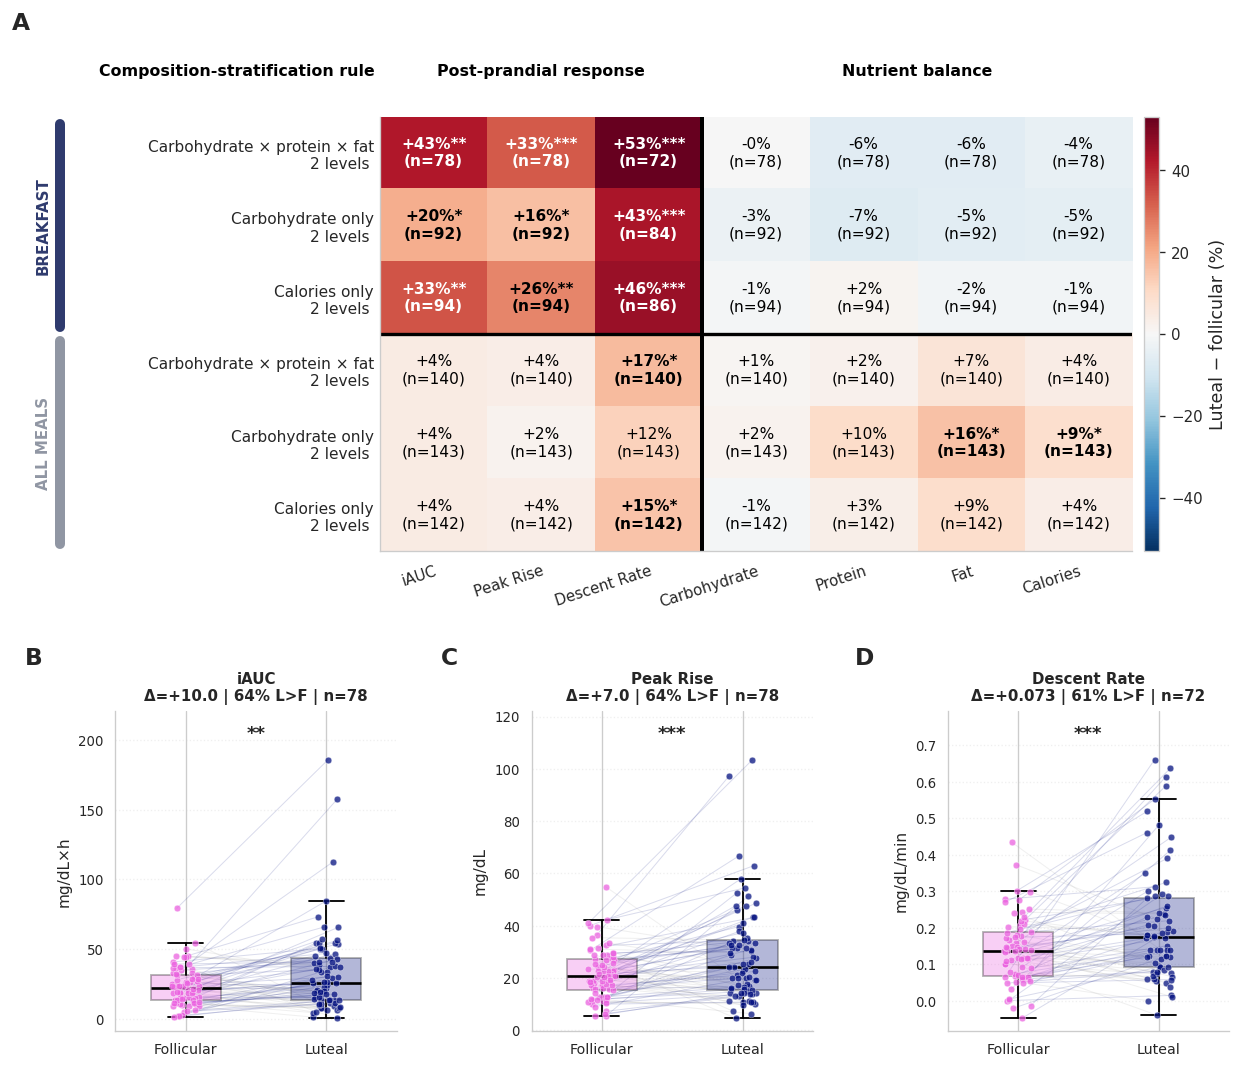

In [12]:
# ================= FIGURE 5 — WITHIN-WOMAN CONFIRMATION =================
# Panels stacked: A heatmap (one row per nutrition-matching rule, simplest -> strictest)
# over B|C|D per-woman paired phase distributions for the first row's rule (carbohydrate only). The canvas is kept
# narrow on purpose: a wide canvas is scaled down more on the page, which shrinks the type.
# Inputs are pre-computed; nothing is fitted here.

fig5_grids = pd.read_csv(F('fig5_grids'))   # SETTINGS BOX
fig5_phase = pd.read_csv(F('fig5_phase'))   # SETTINGS BOX

OUT_LBL = {'true_iAUC': 'iAUC (mg/dL×h)', 'peak_rise': 'Peak Rise (mg/dL)',
           'descent_rate': 'Descent Rate (mg/dL/min)'}
OUTC = ['true_iAUC', 'peak_rise', 'descent_rate']; NO = len(OUTC)
MAC = ['Carbs', 'Protein', 'Fat', 'Energy']
COL_LBL = [OUT_LBL[y].split(' (')[0] for y in OUTC] + ['Carbohydrate', 'Protein', 'Fat', 'Calories']
# The side bars carry the meal window, so rows never repeat "breakfast" / "all meals".
_SPEC_DISPLAY_MAP = {
    'breakfast · carb 2-level': 'Carbohydrate only\n2 levels ',
    'breakfast · total calories 2-level': 'Calories only\n2 levels ',
    'breakfast · carb+prot+fat 2³': 'Carbohydrate × protein × fat\n2 levels ',
    'all meals · carb 2-level': 'Carbohydrate only\n2 levels ',
    'all meals · total calories 2-level': 'Calories only\n2 levels ',
    'all meals · carb+prot+fat 2³': 'Carbohydrate × protein × fat\n2 levels ',
}

gA = fig5_grids[fig5_grids['panel'] == 'A']; gC = fig5_grids[fig5_grids['panel'] == 'C']
_spec = gA[['row', 'spec_label']].drop_duplicates().sort_values('row')
SPEC_LABELS = _spec['spec_label'].tolist(); NR = len(SPEC_LABELS)
def _spec_display(s):
    """Pretty row label. The primary row's spec_label carries a trailing "  (PRIMARY)" tag;
    strip it before the lookup (the row order already carries the primary-first ranking)."""
    _k = ' '.join(str(s).split()).replace(' (PRIMARY)', '')
    return _SPEC_DISPLAY_MAP.get(_k, _k)

SPEC_DISPLAY = [_spec_display(s) for s in SPEC_LABELS]
COLS = OUTC + MAC; NC = len(COLS)

PCT = np.full((NR, NC), np.nan); FDR = np.full((NR, NC), np.nan); NN = np.full((NR, NC), np.nan)
# stars/bold use fdr_grid: BH within four families — breakfast response (9 tests), all-meal
# response (9), breakfast nutrient balance (12), all-meal nutrient balance (12). Breakfast and
# all-meal rules are never pooled.
for src, cols, off in [(gA, OUTC, 0), (gC, MAC, NO)]:
    for _, r in src.iterrows():
        if r['col'] in cols:
            i, j = int(r['row']), off + cols.index(r['col'])
            PCT[i, j] = r['pct']; FDR[i, j] = r['fdr_grid']; NN[i, j] = r['n']
vmax = np.nanmax(np.abs(PCT))

fig = plt.figure(figsize=(11.6, 9.9))   # width set so the 9-pt type matches Figure 4 on the page
# Two independent gridspecs, not one 2-row grid: panel A carries wide left-hand decorations
# (row labels + rotated meal-window bars) that live at negative axes x, so A needs a deep left
# margin while B-D must start near the canvas edge. A shared margin would leave B-D floating
# ~2.5 in from the left once bbox_inches='tight' pads for A's overhang.
gsA = fig.add_gridspec(1, 1, left=0.34, right=0.90, top=0.88, bottom=0.514)
gsB = fig.add_gridspec(1, 3, left=0.15, right=0.95, top=0.38, bottom=0.11, wspace=0.48)

# ===== Panel A — heatmap (rows = matching rule; cols = response | composition) =====
axA = fig.add_subplot(gsA[0])
im = axA.imshow(PCT, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto', origin='upper')
axA.grid(False)
for i in range(NR):
    for j in range(NC):
        if np.isfinite(PCT[i, j]):
            st = pstars(FDR[i, j]); st = '' if st == 'ns' else st
            axA.text(j, i, f"{PCT[i, j]:+.0f}%{st}\n(n={int(NN[i, j])})", ha='center', va='center',
                     fontsize=9.2, color='white' if abs(PCT[i, j]) > 0.6 * vmax else 'black',
                     fontweight='bold' if FDR[i, j] < .05 else 'normal')
axA.set_xticks(range(NC), COL_LBL, fontsize=9, rotation=18, ha='right', rotation_mode='anchor')
axA.set_yticks(range(NR), SPEC_DISPLAY, fontsize=9.2)
axA.tick_params(axis='y', length=0)

# ---- rounded meal-window bars instead of a per-row prefix ----
_win = ['Breakfast only' if str(x).strip().lower().startswith('breakfast') else 'All meal times'
        for x in SPEC_LABELS]
_GC = {'Breakfast only': '#2f3b6e', 'All meal times': '#9096a3'}
_SHORT = {'Breakfast only': 'BREAKFAST', 'All meal times': 'ALL MEALS'}   # full names collide when rotated
_trm = blended_transform_factory(axA.transAxes, axA.transData); _xb = -0.425
_i = 0
while _i < NR:
    _j = _i
    while _j + 1 < NR and _win[_j + 1] == _win[_i]:
        _j += 1
    _c = _GC[_win[_i]]
    axA.plot([_xb, _xb], [_i - 0.40, _j + 0.40], transform=_trm, color=_c, lw=6,
             solid_capstyle='round', clip_on=False, zorder=5)
    axA.text(_xb - 0.022, (_i + _j) / 2.0, _SHORT[_win[_i]], transform=_trm, rotation=90,
             va='center', ha='center', fontsize=9, fontweight='bold', color=_c, clip_on=False)
    _i = _j + 1

_bf = gA[gA['group'] == 'composition control']['row']
if len(_bf): axA.axhline(int(_bf.max()) + 0.5, color='k', lw=2.0)   # breakfast | all-meal sensitivity
axA.axvline(NO - 0.5, color='k', lw=2.4)                            # response | composition divider
axA.text(-0.55, -1.02, 'Composition-stratification rule', ha='right', va='bottom',
         fontsize=9.5, fontweight='bold', color='black', clip_on=False)
axA.text(1, -1.02, 'Post-prandial response', ha='center', va='bottom',
         fontsize=9.5, fontweight='bold', color='black', clip_on=False)
axA.text(NO + (len(MAC) - 1) / 2, -1.02, 'Nutrient balance', ha='center', va='bottom',
         fontsize=9.5, fontweight='bold', color='black', clip_on=False)
axA.text(-0.465, 1.20, 'A', transform=axA.transAxes, fontsize=14, fontweight='bold', ha='right')
cax = make_axes_locatable(axA).append_axes('right', size='2%', pad=0.1)
cb = fig.colorbar(im, cax=cax); cb.set_label('Luteal − follicular (%)', fontsize=10.5)
cb.ax.tick_params(labelsize=9)

# ===== Panels B–D — per-woman phase distributions, first-row rule (box per phase, paired lines) =====
np.random.seed(42)
BOX_OUTC = OUTC   # iAUC, peak rise, descent rate
_PHC = {'Follicular': FOLL, 'Luteal': LUT}
for k, y in enumerate(BOX_OUTC):
    axb = fig.add_subplot(gsB[k])
    _u = OUT_LBL[y].split('(')[1].rstrip(')')   # outcome's own units
    wy = (fig5_phase[fig5_phase['outcome'] == y]
          .pivot(index='subj', columns='phase', values='value')
          .dropna(subset=['Follicular', 'Luteal']))
    fv, lv = wy['Follicular'].values, wy['Luteal'].values; dv = lv - fv
    jf = np.random.uniform(-.10, .10, len(fv)); jl = np.random.uniform(-.10, .10, len(lv))
    for xf, xl, a, b in zip(jf, 1 + jl, fv, lv):   # paired connective line per woman
        axb.plot([xf, xl], [a, b], color=(LUT if b > a else '0.6'), lw=.6, alpha=.15, zorder=1)
    bp = axb.boxplot([fv, lv], positions=[0, 1], widths=.5, showfliers=False, patch_artist=True,
                     zorder=2, medianprops=dict(color='k', lw=1.6), whiskerprops=dict(color='k', lw=1.1),
                     capprops=dict(color='k', lw=1.1), boxprops=dict(color='k', lw=1.1))
    for _bx, _ph in zip(bp['boxes'], ['Follicular', 'Luteal']): _bx.set(facecolor=_PHC[_ph], alpha=.30)
    axb.scatter(jf, fv, color=FOLL, alpha=.75, s=16, edgecolor='white', lw=.3, zorder=3)
    axb.scatter(1 + jl, lv, color=LUT, alpha=.75, s=16, edgecolor='white', lw=.3, zorder=3)
    axb.set_xticks([0, 1], ['Follicular', 'Luteal'], fontsize=8.5); axb.set_xlim(-.5, 1.5)
    # units live on the y axis, so the Δ line omits them or the three titles collide
    axb.set_title(f"{OUT_LBL[y].split(' (')[0]}\nΔ={_fd(float(dv.mean()))} | "
                  f"{100*np.mean(dv>0):.0f}% L>F | n={len(dv)}", fontsize=9.0, weight='bold')
    axb.set_ylabel(_u, fontsize=9.2); axb.grid(True, axis='y', ls=':', alpha=.3); sns.despine(ax=axb)
    # L-F stars (no bracket line): they ARE panel A's primary-row cell (row 0, fdr_grid) for this outcome -- the
    # same paired test on the same women -- so B-D can never disagree with A. Guard: same n.
    _j = OUTC.index(y)
    assert int(NN[0, _j]) == len(dv), f"{y}: panel A row 0 n={NN[0, _j]:.0f} but fig5_phase n={len(dv)}"
    _st = pstars(FDR[0, _j])
    if _st and _st != 'ns':
        _lo, _hi = float(np.nanmin(np.r_[fv, lv])), float(np.nanmax(np.r_[fv, lv])); _rg = _hi - _lo
        _yb, _h = _hi + 0.04 * _rg, 0.025 * _rg
        axb.text(0.5, _yb + _h, _st, ha='center', va='bottom', fontsize=11, fontweight='bold')
        axb.set_ylim(top=_yb + 0.15 * _rg)
    axb.text(-0.26, 1.20, ['B', 'C', 'D'][k], transform=axb.transAxes, fontsize=14,
             fontweight='bold', ha='right', va='top')

savefig('Figure5'); plt.show()

---
## Figure 6 - activity independence + subgroups

# Figure 6 — Behavioral robustness and covariate interactions of the glucose-variability cycle

A single landscape figure showing that the glucose-variability cycle is robust to adjustment for recorded activity, in four panels:

- **A** recorded physical activity varies across the cycle;
- **B** unadjusted and activity-adjusted CV curves are compared directly;
- **C** attenuation estimates and confidence intervals for each confirmed variability metric;
- **D** age, BMI, carbohydrate, and activity × cycle-spline interaction tests are summarized.

**Data.** `data/figure_panels.csv`, `data/fig6_activity_summary.csv`, `data/fig6_activity_curves.csv`, `data/fig6_activity_interaction.csv` and `data/fig6_covariate_interaction.csv` (N = 2132 diet-complete subject-days for every panel, matching Figure 3).

In [13]:
# === Setup: imports, style, constants ===

sns.set_style('whitegrid')
np.random.seed(42)
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'figure.dpi': 120, 'savefig.dpi': 300, 'axes.linewidth': 0.8,
})

FINAL = '.'
CLEAN = '.'
SUBJECT_ID_COL = 'RegistrationCode'

FOLL_COLOR = '#eb63e0'; LUT_COLOR = '#051281'      # phase colors (fixed)
PEAK_C = '#D67173'; NADIR_C = '#78C9C7'
VARM = ['CV', 'SD', 'MAGE', 'RANGE']
os.makedirs('figures', exist_ok=True)

In [14]:
# === Panels A/B/C data: activity (saved artifacts, no R re-run) ===
fd = pd.read_csv(F('figure_data'))          # SETTINGS BOX
ap = fd[(fd['source'] == 'exercise') & (fd['metric'] == 'active_prob')]
apb = ap[ap['series'] == 'binned'].sort_values('x')          # binned P(exercise) means
aps = ap[ap['series'] == 'spline'].sort_values('x')          # GLMM spline (200 pts)
A_p_fdr = float(aps['p_fdr'].iloc[0]); A_p_perm = float(aps['p_perm'].iloc[0])
gmA = np.average(apb['y'].values, weights=apb['n'].values)   # overall P(exercise)

summ = pd.read_csv(F('exercise_summary')).set_index('Metric')   # SETTINGS BOX
crit = chi2.ppf(0.95, 4)                                     # cycle-spline LRT df=4
print('Activity: GLMM p=%.4f, perm p=%.4f, overall P(exercise)=%.3f' % (A_p_fdr, A_p_perm, gmA))
print(summ)

Activity: GLMM p=0.0115, perm p=0.0167, overall P(exercise)=0.233
           N  n_subj  LRT_unadj  LRT_adj  dLRT  q_cycle_adj  p_active  \
Metric                                                                  
CV      2113     209    19.4680  18.8928 -0.58       0.0047    0.3063   
SD      2113     209    16.3329  15.6715 -0.66       0.0047    0.2338   
MAGE    2113     209    15.9531  15.4055 -0.55       0.0047    0.2331   
RANGE   2113     209    16.3101  16.1815 -0.13       0.0047    0.8954   
MAG     2113     209    16.8475  16.4613 -0.39       0.0047    0.4272   
SDWSH   2113     209    13.3167  12.9772 -0.34       0.0114    0.5703   

        pct_mediated  med_CI_lo  med_CI_hi  p_indirect  amp_unadj  amp_adj  \
Metric                                                                       
CV            1.3836    -6.5193     7.5663       0.492     8.9510   8.8272   
SD            1.8435    -2.8221     7.9113       0.368     8.5115   8.3546   
MAGE          1.6546    -5.8439     9

[Fig6D] one FDR family of 24 tests: BH boundary p=0.0146 -> LRT 12.40


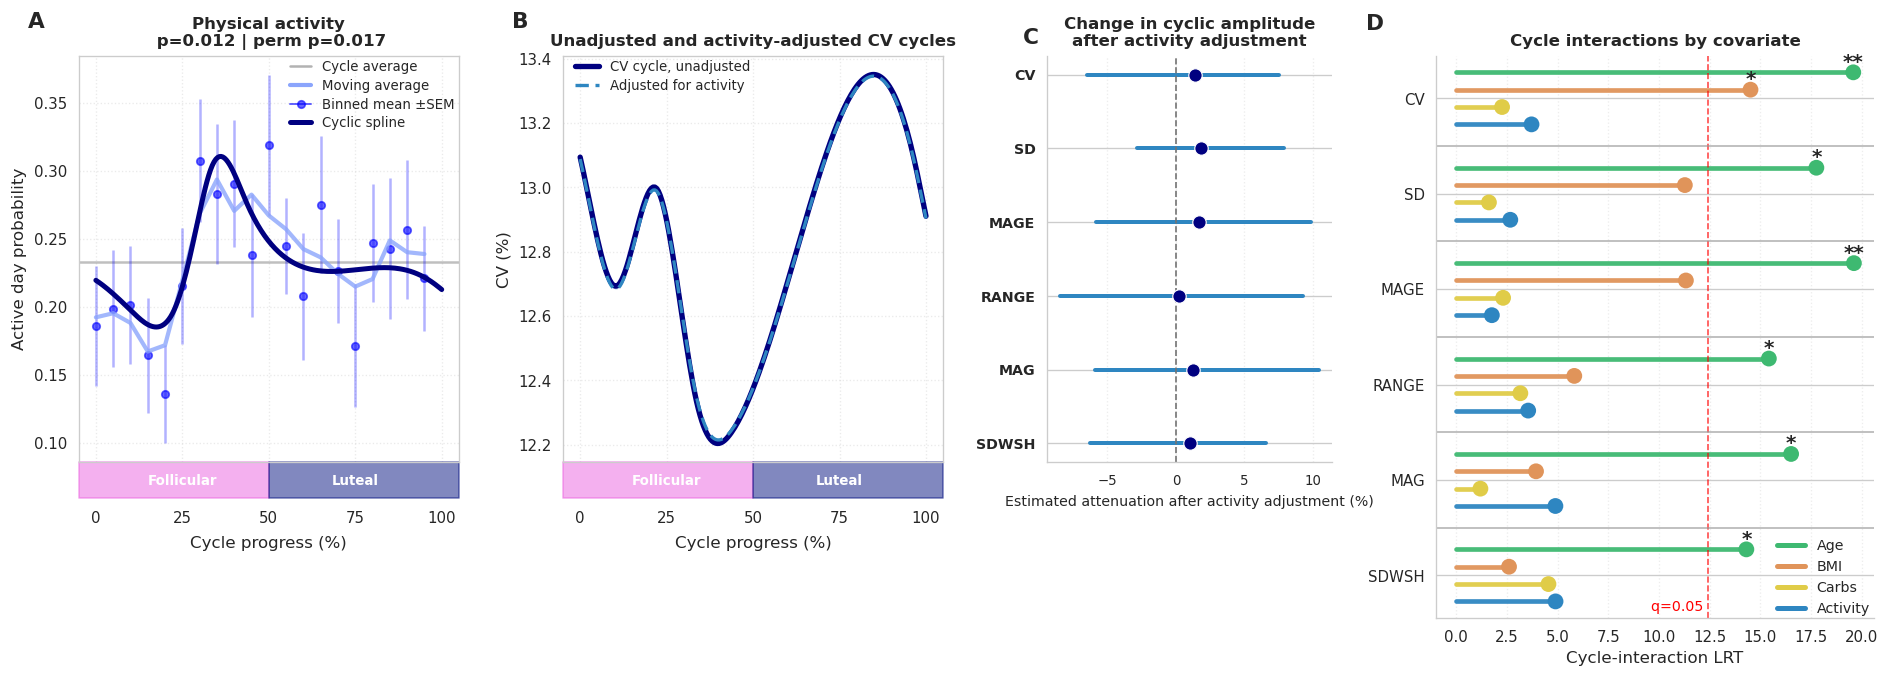

Saved: figures/Figure6.{png,pdf}

--- ATTENUATION after activity adjustment ---
CV    attenuation  +1% [-7,+8] p=0.49
SD    attenuation  +2% [-3,+8] p=0.37
MAGE  attenuation  +2% [-6,+10] p=0.42
RANGE attenuation  +0% [-8,+9] p=0.92
MAG   attenuation  +1% [-6,+10] p=0.62
SDWSH attenuation  +1% [-6,+7] p=0.63

--- covariate x cycle interactions (one 24-test BH family) ---
CV     Age q=0.0072  BMI q=0.0218  Carbs q=0.7856  Activity q=0.7050
SD     Age q=0.0109  BMI q=0.0629  Carbs q=0.8410  Activity q=0.7856
MAGE   Age q=0.0072  BMI q=0.0629  Carbs q=0.7856  Activity q=0.8410
RANGE  Age q=0.0187  BMI q=0.5100  Carbs q=0.7490  Activity q=0.7050
MAG    Age q=0.0143  BMI q=0.7050  Carbs q=0.8789  Activity q=0.5965
SDWSH  Age q=0.0218  BMI q=0.7856  Carbs q=0.6211  Activity q=0.5965


In [15]:
FIGOUT = globals().get('FIGOUT') or os.environ.get('FIGOUT', 'figures'); os.makedirs(FIGOUT, exist_ok=True)   # set in the SETTINGS BOX (top of notebook)
# === Figure6 — activity adjustment and covariate interactions ===
# Landscape 1x4 grid:
#   A activity is cyclic   B adjust-for-activity overlay   C attenuation forest   D interaction tests

def _stars(p): return '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < 0.05 else 'n.s.'

_xp = np.linspace(0, 100, 200)
BAR_IN = 0.30          # phase-bar height in INCHES, as in Figure 3
def _pbar(ax, fs=8):
    # Height is fixed in inches (not axes fraction) so the bar and the tick padding stay
    # in step when panels change height; a fraction would grow with a taller panel and
    # the x tick labels would ride up into the bar.
    ax.set_xlim(-5, 105); tr = ax.get_xaxis_transform()
    _ax_in = ax.get_position().height * ax.figure.get_figheight()
    _f = BAR_IN / _ax_in
    ax.fill_between([-5, 50], -_f, 0, color=FOLL_COLOR, alpha=0.5, transform=tr, clip_on=False)
    ax.fill_between([50, 105], -_f, 0, color=LUT_COLOR, alpha=0.5, transform=tr, clip_on=False)
    ax.text(25, -_f * 0.62, 'Follicular', transform=tr, ha='center', color='white', fontweight='bold', fontsize=fs)
    ax.text(75, -_f * 0.62, 'Luteal', transform=tr, ha='center', color='white', fontweight='bold', fontsize=fs)
    ax.tick_params(axis='x', pad=BAR_IN * 72 + 4)   # clear the bar, then a small gap

UNADJ_C = 'navy'; ADJ_C = '#2E86C1'      # unadjusted / activity-adjusted CV curves

# Two rows so D can be taller than A-C: A-C occupy the top row, D spans both rows.
# (height_ratios takes one entry per ROW, so a 1x4 grid cannot express this.)
figB = plt.figure(figsize=(17, 6))
gs = figB.add_gridspec(2, 4, width_ratios=[1, 1, 0.75, 1.15], height_ratios=[1, 0.35],
                       wspace=0.28, hspace=0.05, left=0.05, right=0.93, top=0.88, bottom=0.10)
axA = figB.add_subplot(gs[0, 0]); axO = figB.add_subplot(gs[0, 1])
axB = figB.add_subplot(gs[0, 2]); axS = figB.add_subplot(gs[:, 3])

# ---- A: activity itself cycles ----
yA = aps['y'].values; yA = yA - yA.mean() + gmA
axA.axhline(gmA, color='gray', lw=1.5, alpha=0.5)
axA.errorbar(apb['x'], apb['y'], yerr=apb['sem'], fmt='none', ecolor='blue', alpha=0.3)
axA.scatter(apb['x'], apb['y'], color='blue', s=20, alpha=0.6)
axA.plot(apb['x'], apb['y'].rolling(3, center=True, min_periods=1).mean(), color='#8ba5fc', lw=2.5, alpha=0.8)
axA.plot(_xp, yA, color='navy', lw=3)
axA.set_title('Physical activity\n p=%.3f | perm p=%.3f' % (A_p_fdr, A_p_perm), fontsize=10, fontweight='bold')
axA.set_ylabel('Active day probability', fontsize=10); _pbar(axA)
axA.set_xticks([0,25,50,75,100]); axA.tick_params(labelsize=9)
axA.set_xlabel('Cycle progress (%)', fontsize=10, labelpad=6); axA.grid(True, ls=':', alpha=0.4)
_legA = [Line2D([0],[0], color='gray', lw=1.5, alpha=0.6, label='Cycle average'),
         Line2D([0],[0], color='#8ba5fc', lw=2.5, label='Moving average'),
         Line2D([0],[0], marker='o', color='blue', ls='-', lw=1.2, ms=4.5, alpha=0.6, label='Binned mean ±SEM'),
         Line2D([0],[0], color='navy', lw=3, label='Cyclic spline')]
axA.legend(handles=_legA, loc='upper right', bbox_to_anchor=(1.02, 1.02), fontsize=8, frameon=False, handlelength=1.6, labelspacing=0.35)
axA.text(-0.09, 1.06, 'A', transform=axA.transAxes, fontsize=13, fontweight='bold', va='bottom', ha='right')

# ---- B: OVERLAY — activity-adjusted CV curve lies on the unadjusted cycle ----
PREDc = pd.read_csv(F('activity_pred'))   # SETTINGS BOX
_dC = PREDc[PREDc['metric'] == 'CV'].sort_values('cycle')
_maxdC = float((_dC['pred_adj'] - _dC['pred_unadj']).abs().max())
axO.fill_between(_dC['cycle'], _dC['pred_unadj'], _dC['pred_adj'], color=ADJ_C, alpha=0.30, lw=0, zorder=1)
axO.plot(_dC['cycle'], _dC['pred_unadj'], color=UNADJ_C, lw=3.2, zorder=3)
axO.plot(_dC['cycle'], _dC['pred_adj'], color=ADJ_C, lw=2.0, ls=(0, (4, 2)), zorder=4)
_pbar(axO)
axO.set_xticks([0, 25, 50, 75, 100]); axO.tick_params(labelsize=9)
axO.set_xlabel('Cycle progress (%)', fontsize=10, labelpad=6); axO.set_ylabel('CV (%)', fontsize=10)
axO.set_title('Unadjusted and activity-adjusted CV cycles', fontsize=10, fontweight='bold')
axO.grid(True, ls=':', alpha=0.4)
_legO = [Line2D([0],[0], color=UNADJ_C, lw=3.2, label='CV cycle, unadjusted'),
         Line2D([0],[0], color=ADJ_C, lw=2.0, ls=(0, (4, 2)), label='Adjusted for activity')]
axO.legend(handles=_legO, loc='upper left', bbox_to_anchor=(0, 1.02), fontsize=8, frameon=False, handlelength=1.8, labelspacing=0.35)
axO.text(-0.09, 1.06, 'B', transform=axO.transAxes, fontsize=13, fontweight='bold', va='bottom', ha='right')

# ---- C: ATTENUATION forest — descriptive adjustment, not causal mediation ----
_amets = ['CV', 'SD', 'MAGE', 'RANGE', 'MAG', 'SDWSH']
_ay = np.arange(len(_amets))[::-1]
for _i, _m in enumerate(_amets):
    _r = summ.loc[_m]
    _est = float(_r['pct_mediated']); _lo = float(_r['med_CI_lo']); _hi = float(_r['med_CI_hi'])
    axB.plot([_lo, _hi], [_ay[_i], _ay[_i]], color=ADJ_C, lw=2.4, zorder=2)
    axB.scatter(_est, _ay[_i], s=65, color=UNADJ_C, edgecolor='white', linewidth=0.7, zorder=3)
axB.axvline(0, color='0.45', lw=1.0, ls='--')
axB.set_yticks(_ay); axB.set_yticklabels(_amets, fontsize=8.5, fontweight='bold')
axB.set_xlabel('Estimated attenuation after activity adjustment (%)', fontsize=8.5)
axB.set_title('Change in cyclic amplitude\nafter activity adjustment', fontsize=10, fontweight='bold')
axB.grid(True, axis='x', ls=':', alpha=0.35)
for _s in ['top','right']: axB.spines[_s].set_visible(False)
axB.text(-0.03, 1.02, 'C', transform=axB.transAxes, fontsize=13, fontweight='bold', va='bottom', ha='right')

# ---- D: covariate-by-cycle interaction tests ----
CCOL4 = {'age':'#3EB971', 'bmi':'#E0945A', 'activity':'#2E86C1', 'Carbohydrates':'#E0CC48'}
CLAB4 = {'age':'Age', 'bmi':'BMI', 'activity':'Activity', 'Carbohydrates':'Carbs'}
COV4  = ['age', 'bmi', 'Carbohydrates', 'activity']
METC = _amets   # every confirmed variability metric, same order as panel C
def _cstar(q): return '***' if q<1e-3 else '**' if q<1e-2 else '*' if q<.05 else 'n.s.'
_INTc = pd.read_csv(F('fig3_robustness')); _IQc = {(r['metric'],r['covariate']):r for _,r in _INTc.iterrows()}
_ACTc = {r['metric']:r for _,r in pd.read_csv(F('activity_inter')).iterrows()}
# ONE FDR family for every covariate x cycle interaction: len(_amets) metrics x 4 modifiers,
# pooled across the two source files (their own int_fdr columns are per-file and are
# deliberately not used here). 24 tests at 6 metrics; the size is asserted below, never assumed.
def _bh(pv):
    pv = np.asarray(pv, float); m = len(pv); o = np.argsort(pv)
    adj = np.empty(m)
    adj[o] = np.minimum(np.minimum.accumulate((pv[o] * m / np.arange(1, m + 1))[::-1])[::-1], 1.0)
    return adj
_pool = ([( (r['metric'], r['covariate']), float(r['int_lrt']), float(r['int_p']) ) for _, r in _INTc.iterrows()]
         + [((m, 'activity'), float(_ACTc[m]['int_lrt']), float(_ACTc[m]['int_p'])) for m in _ACTc])
assert len(_pool) == len(_amets) * len(COV4), (
    f'Fig6D family is {len(_pool)}, expected {len(_amets) * len(COV4)} '
    f'({len(_amets)} metrics x {len(COV4)} modifiers). A metric missing from '
    f'fig3_cycle_robustness.csv or activity_cycle_interaction.csv shrinks the BH denominator '
    f'silently -- re-run figure6_analyses.ipynb with the same VAR_METRICS.')
_QJOINT = dict(zip([k for k, _, _ in _pool], _bh([pv for _, _, pv in _pool])))
_LRTJ = {k: ev for k, ev, _ in _pool}
def _cevi(met, cov):
    return _LRTJ[(met, cov)], float(_QJOINT[(met, cov)])
# FDR (q=0.05) threshold in LRT space: BH step-up boundary on the raw p's of the single
# pooled family, mapped back through the chi2(4) quantile.
def _bh_bound(pv, alpha=0.05):
    pv = np.sort(np.asarray(pv, float)); m = len(pv)
    k = np.where(pv <= (np.arange(1, m + 1) / m) * alpha)[0]
    return (k.max() + 1) / m * alpha if len(k) else alpha / m
_qb = _bh_bound([pv for _, _, pv in _pool])
PLINE = float(chi2.isf(_qb, df=4))
print(f'[Fig6D] one FDR family of {len(_pool)} tests: BH boundary p={_qb:.4f} -> LRT {PLINE:.2f}')
STEP=0.80; GAP=1.20; yy=0; yt=[]; yl=[]; _ally=[]   # tighter gap: one block per metric, not three
for met in METC[::-1]:
    _grp=[]
    for cov in COV4[::-1]:            # reversed so top->bottom = age, bmi, carbs, activity
        ev,q = _cevi(met,cov)
        axS.plot([0,ev],[yy,yy], color=CCOL4[cov], lw=2.8, alpha=.95, zorder=2)
        axS.scatter(ev, yy, s=90, color=CCOL4[cov], edgecolor='none', zorder=3)
        st = _cstar(q)
        if st!='n.s.': axS.text(ev, yy+0.04, st, ha='center', va='bottom', fontsize=12, fontweight='bold')
        _grp.append(yy); _ally.append(yy); yy += STEP
    yt.append(sum(_grp)/len(_grp)); yl.append(met); yy += GAP
_ylo, _yhi = min(_ally), max(_ally)
axS.axvline(PLINE, color='r', ls='--', lw=1, alpha=.7)
axS.text(PLINE, _ylo-0.55, 'q=0.05 ', color='r', fontsize=8.5, va='bottom', ha='right')
axS.set_yticks(yt); axS.set_yticklabels(yl, fontsize=9); axS.set_ylim(_ylo-0.75, _yhi+0.75); axS.tick_params(axis='x', labelsize=9)
axS.set_xlabel('Cycle-interaction LRT', fontsize=10)
axS.set_title('Cycle interactions by covariate', fontsize=10, fontweight='bold')
axS.grid(True, axis='x', ls=':', alpha=.35)
for _mid in [(yt[_i]+yt[_i+1])/2 for _i in range(len(yt)-1)]: axS.axhline(_mid, color='0.6', lw=0.9, alpha=0.8)
_lh = [Line2D([0],[0], color=CCOL4[c], lw=3, label=CLAB4[c]) for c in COV4]
axS.legend(handles=_lh, fontsize=8.5, frameon=False, loc='lower right', bbox_to_anchor=(1.02, -0.02), ncol=1)
for _s in ['top','right']: axS.spines[_s].set_visible(False)
axS.text(-0.12, 1.04, 'D', transform=axS.transAxes, fontsize=13, fontweight='bold', va='bottom', ha='right')

figB.savefig(f'{FIGOUT}/Figure6.png', dpi=300, bbox_inches='tight', facecolor='white')
figB.savefig(f'{FIGOUT}/Figure6.pdf', bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: figures/Figure6.{png,pdf}')

print('\n--- ATTENUATION after activity adjustment ---')
for m in [x for x in _amets if x in summ.index]:
    r = summ.loc[m]
    print('%-5s attenuation %+3.0f%% [%+.0f,%+.0f] p=%.2f' % (m, r['pct_mediated'], r['med_CI_lo'], r['med_CI_hi'], r['p_indirect']))

print(f'\n--- covariate x cycle interactions (one {len(_pool)}-test BH family) ---')
for _m in _amets:
    print('%-6s ' % _m + '  '.join('%s q=%.4f' % (CLAB4[_c], _QJOINT[(_m, _c)]) for _c in COV4))